# BigFlow NIDS V2 



## EL PROBLEMA

Un centro de operaciones de seguridad recibe millones de conexiones por dia. De
todas, un punado son un ataque, y revisarlas a mano es imposible. Las reglas
tradicionales por firma funcionan bien para lo que ya esta catalogado, pero solo
detectan lo que alguien escribio antes: un ataque nuevo pasa derecho.

Lo que hay para trabajar no son los paquetes, es el resumen de cada conversacion
entre dos maquinas: cuanto duro, cuantos paquetes fueron y volvieron, de que
tamano, con que banderas TCP y a que ritmo. Eso es un flujo de red, y es lo que
trae este dataset.

### Que tipo de problema es

El trabajo junta dos de los tipos vistos en el curso, y es a proposito:

- **Clasificacion supervisada.** Con los flujos ya etiquetados se entrena un
  modelo que diga si un flujo es ataque (`Label`) y de que tipo (`Attack`).
- **Deteccion de anomalias, no supervisada.** Se modela como es el trafico normal
  usando *solo* flujos benignos y se marca lo que se desvia, sin ver ni un ataque
  durante el entrenamiento.

El segundo existe porque el primero tiene un limite: solo reconoce lo que ya vio.
Una empresa si tiene registros de su trafico normal, pero no tiene ataques
etiquetados de su propia red, y el ataque que importa es el que todavia no esta
en ningun dataset.

### Por que importa equivocarse poco, y de que lado

Los dos errores posibles no cuestan lo mismo:

| Error | Que pasa | Costo |
|---|---|---|
| Falso negativo | un ataque real pasa sin que nadie lo vea | brecha de seguridad, datos robados |
| Falso positivo | trafico normal genera una alerta | tiempo del analista, y si son muchas se deja de creer en el sistema |

De aca sale una decision que atraviesa todo el notebook: **la accuracy no sirve
como metrica en este problema.** Con un 42% de trafico benigno, un modelo que
responda "todo es ataque" saca 58% de accuracy sin haber aprendido nada. Se
evalua con recall por clase, F1 macro, y recall a un presupuesto fijo de falsas
alarmas.

### Que decisiones mejora

1. Priorizar la cola de alertas, para que el analista atienda primero lo que el
   modelo marca con mas confianza y no lo que llego primero.
2. Enrutar la respuesta, porque un DDoS se atiende con mitigacion de red y un
   ataque de credenciales con bloqueo de cuentas.
3. No esconder lo desconocido: una alerta que dice "esto es raro pero no se que
   es" es informacion util; una que dice "DDoS" cuando no lo es manda al analista
   por el camino equivocado.

# Diccionario de datos – BigFlow-NIDS

## 1. Descripción general

**BigFlow-NIDS** es un conjunto de datos diseñado para la investigación y el desarrollo de sistemas de detección de intrusiones en redes (Network Intrusion Detection Systems – NIDS), mediante técnicas de análisis de datos, Big Data y aprendizaje automático.

El dataset integra información de tráfico de red procedente de cuatro conjuntos de datos de referencia:

- NF-UNSW-NB15-v3.
- NF-ToN-IoT-v3.
- NF-BoT-IoT-v3.
- NF-CSE-CIC-IDS2018-v3.

Su propósito es facilitar la identificación y clasificación de comportamientos normales y actividades maliciosas dentro del tráfico de red.

### 1.1. Características generales

| Característica | Descripción |
|---|---|
| Nombre | BigFlow-NIDS |
| Versión | 2 |
| Dominio | Ciberseguridad y detección de intrusiones |
| Registros | 66.935.021 flujos de red |
| Variables | 55 atributos |
| Categorías | 32 clases de tráfico |
| Formatos | CSV y Parquet |
| Unidad de observación | Flujo de red (Network Flow) |
| Procesamiento | Apache Spark |
| Tarea analítica | Clasificación binaria y multiclase |

## 2. Diccionario de variables

Las variables se organizan en ocho grupos funcionales para facilitar su interpretación y posterior selección en los modelos analíticos.



### 2.1. Información temporal y duración del flujo

| Variable | Descripción | Tipo  |
|---|---|---|
| FLOW_START_MILLISECONDS | Marca temporal que identifica el momento de inicio del flujo de red, expresada en milisegundos. | Numérico entero / timestamp |
| FLOW_END_MILLISECONDS | Marca temporal correspondiente al momento de finalización del flujo de red, expresada en milisegundos. | Numérico entero / timestamp |
| FLOW_DURATION_MILLISECONDS | Tiempo total transcurrido durante el flujo de comunicación, expresado en milisegundos. | Numérico |
| DURATION_IN | Duración asociada al tráfico de entrada del flujo. | Numérico |
| DURATION_OUT | Duración asociada al tráfico de salida del flujo. | Numérico |

### 2.2. Identificación de origen, destino y protocolos

| Variable | Descripción | Tipo |
|---|---|---|
| IPV4_SRC_ADDR | Dirección IPv4 del dispositivo que origina el flujo de comunicación. | Categórico / dirección IP |
| L4_SRC_PORT | Número del puerto de origen correspondiente a la capa de transporte. | Numérico entero |
| IPV4_DST_ADDR | Dirección IPv4 del dispositivo que recibe el flujo de comunicación. | Categórico / dirección IP |
| L4_DST_PORT | Número del puerto de destino correspondiente a la capa de transporte. | Numérico entero |
| PROTOCOL | Identificador numérico del protocolo de transporte utilizado en la comunicación, por ejemplo TCP, UDP o ICMP. | Categórico |
| L7_PROTO | Identificador del protocolo de aplicación asociado al tráfico de red. | Categórico |

### 2.3. Volumen de tráfico y cantidad de paquetes

| Variable | Descripción | Tipo  |
|---|---|---|
| IN_BYTES | Cantidad de bytes transferidos en la dirección de entrada del flujo. | Numérico entero |
| IN_PKTS | Cantidad de paquetes registrados en la dirección de entrada. | Numérico entero |
| OUT_BYTES | Cantidad de bytes transferidos en la dirección de salida del flujo. | Numérico entero |
| OUT_PKTS | Cantidad de paquetes registrados en la dirección de salida. | Numérico entero |
| NUM_PKTS_UP_TO_128_BYTES | Cantidad de paquetes cuyo tamaño es de hasta 128 bytes. | Numérico entero |
| NUM_PKTS_128_TO_256_BYTES | Cantidad de paquetes cuyo tamaño se encuentra entre 128 y 256 bytes. | Numérico entero |
| NUM_PKTS_256_TO_512_BYTES | Cantidad de paquetes cuyo tamaño se encuentra entre 256 y 512 bytes. | Numérico entero |
| NUM_PKTS_512_TO_1024_BYTES | Cantidad de paquetes cuyo tamaño se encuentra entre 512 y 1024 bytes. | Numérico entero |
| NUM_PKTS_1024_TO_1514_BYTES | Cantidad de paquetes cuyo tamaño se encuentra entre 1024 y 1514 bytes. | Numérico entero |

### 2.4. Características de los paquetes y protocolo TCP

| Variable | Descripción | Tipo  |
|---|---|---|
| TCP_FLAGS | Indicadores o banderas TCP observados en el flujo de comunicación. | Categórico / bitmask |
| CLIENT_TCP_FLAGS | Banderas TCP asociadas al extremo cliente de la comunicación. | Categórico / bitmask |
| SERVER_TCP_FLAGS | Banderas TCP asociadas al extremo servidor de la comunicación. | Categórico / bitmask |
| MIN_TTL | Valor mínimo del campo Time To Live (TTL) identificado en los paquetes del flujo. | Numérico entero |
| MAX_TTL | Valor máximo del campo Time To Live (TTL) identificado en los paquetes del flujo. | Numérico entero |
| LONGEST_FLOW_PKT | Tamaño del paquete más grande observado dentro del flujo. | Numérico |
| SHORTEST_FLOW_PKT | Tamaño del paquete más pequeño observado dentro del flujo. | Numérico |
| MIN_IP_PKT_LEN | Longitud mínima registrada para los paquetes IP del flujo. | Numérico |
| MAX_IP_PKT_LEN | Longitud máxima registrada para los paquetes IP del flujo. | Numérico |
| TCP_WIN_MAX_IN | Tamaño máximo de ventana TCP observado en la dirección de entrada. | Numérico entero |
| TCP_WIN_MAX_OUT | Tamaño máximo de ventana TCP observado en la dirección de salida. | Numérico entero |

### 2.5. Rendimiento y retransmisión de paquetes

| Variable | Descripción | Tipo  |
|---|---|---|
| SRC_TO_DST_SECOND_BYTES | Cantidad de bytes transferidos por segundo desde el origen hacia el destino. | Numérico |
| DST_TO_SRC_SECOND_BYTES | Cantidad de bytes transferidos por segundo desde el destino hacia el origen. | Numérico |
| RETRANSMITTED_IN_BYTES | Cantidad de bytes retransmitidos en la dirección de entrada. | Numérico |
| RETRANSMITTED_IN_PKTS | Cantidad de paquetes retransmitidos en la dirección de entrada. | Numérico entero |
| RETRANSMITTED_OUT_BYTES | Cantidad de bytes retransmitidos en la dirección de salida. | Numérico |
| RETRANSMITTED_OUT_PKTS | Cantidad de paquetes retransmitidos en la dirección de salida. | Numérico entero |
| SRC_TO_DST_AVG_THROUGHPUT | Rendimiento promedio de transferencia de datos desde el origen hacia el destino. | Numérico |
| DST_TO_SRC_AVG_THROUGHPUT | Rendimiento promedio de transferencia de datos desde el destino hacia el origen. | Numérico |

### 2.6. Características de protocolos específicos

| Variable | Descripción | Tipo  |
|---|---|---|
| ICMP_TYPE | Tipo de mensaje ICMP identificado en el tráfico de red. | Categórico / numérico |
| ICMP_IPV4_TYPE | Tipo de mensaje ICMP correspondiente al protocolo IPv4. | Categórico / numérico |
| DNS_QUERY_ID | Identificador asociado a una consulta DNS. | Numérico entero |
| DNS_QUERY_TYPE | Tipo de consulta DNS realizada, por ejemplo, solicitud de registro A o AAAA. | Categórico |
| DNS_TTL_ANSWER | Valor Time To Live asociado a las respuestas DNS. | Numérico |
| FTP_COMMAND_RET_CODE | Código de respuesta retornado por el servidor FTP ante una solicitud o comando. | Numérico / categórico |

### 2.7. Estadísticas de tiempo entre paquetes (IAT)

IAT (Inter-Arrival Time) representa el intervalo temporal entre la llegada de paquetes consecutivos. Estas variables permiten estudiar los patrones de comunicación y el comportamiento temporal del tráfico.

| Variable | Descripción | Tipo  |
|---|---|---|
| SRC_TO_DST_IAT_MIN | Intervalo mínimo entre paquetes consecutivos desde el origen hacia el destino. | Numérico |
| SRC_TO_DST_IAT_MAX | Intervalo máximo entre paquetes consecutivos desde el origen hacia el destino. | Numérico |
| SRC_TO_DST_IAT_AVG | Intervalo promedio entre paquetes consecutivos desde el origen hacia el destino. | Numérico |
| SRC_TO_DST_IAT_STDDEV | Desviación estándar de los intervalos entre paquetes desde el origen hacia el destino. | Numérico |
| DST_TO_SRC_IAT_MIN | Intervalo mínimo entre paquetes consecutivos desde el destino hacia el origen. | Numérico |
| DST_TO_SRC_IAT_MAX | Intervalo máximo entre paquetes consecutivos desde el destino hacia el origen. | Numérico |
| DST_TO_SRC_IAT_AVG | Intervalo promedio entre paquetes consecutivos desde el destino hacia el origen. | Numérico |
| DST_TO_SRC_IAT_STDDEV | Desviación estándar de los intervalos entre paquetes desde el destino hacia el origen. | Numérico |

### 2.8. Variables objetivo o de clasificación

| Variable | Descripción | Tipo  |
|---|---|---|
| Label | Etiqueta que identifica si el flujo corresponde a tráfico legítimo o malicioso. Se utiliza para clasificación binaria. | Categórico binario |
| Attack | Categoría específica que identifica el tipo de tráfico o ataque registrado. Permite desarrollar modelos de clasificación multiclase. | Categórico |

## 3. Variables objetivo y enfoque de modelado

El conjunto de datos permite abordar dos problemas de clasificación:

**Clasificación binaria**

Busca determinar si un flujo de red corresponde a tráfico legítimo o malicioso.

- Label = 0: tráfico benigno.
- Label = 1: tráfico asociado a un ataque.

**Clasificación multiclase**

Busca identificar la categoría específica de la actividad registrada mediante la variable Attack.

El conjunto contempla 32 categorías, incluyendo tráfico benigno y diferentes modalidades de ataques informáticos.


## 1. Librerias

In [1]:
import os
import gc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.utils import resample
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    confusion_matrix,          # Matriz de confusion
    classification_report,     # Reporte completo de metricas
    accuracy_score,            # Exactitud global
    precision_score,           # Precision
    recall_score,              # Sensibilidad / Recall
    f1_score,                  # F1-Score
    balanced_accuracy_score,   # Exactitud balanceada
    roc_auc_score,             # Area bajo la curva ROC
    roc_curve,                 # Curva ROC completa
    precision_recall_curve,    # Curva Precision-Recall
    average_precision_score    # PR-AUC
)

SEMILLA = 42

print("pandas:", pd.__version__)


pandas: 3.0.5


## 2. Ruta relativa al archivo

El notebook esta en la raiz del repositorio, por eso la ruta es `data/<archivo>.parquet`.
Para cargar otra particion solo cambia el nombre del archivo en `ARCHIVO`.

In [2]:
CARPETA_DATOS = "data"
ARCHIVO = "merged_part_1.parquet"

RUTA_PARQUET = os.path.join(CARPETA_DATOS, ARCHIVO)

print("Ruta relativa :", RUTA_PARQUET)
print("Existe        :", os.path.exists(RUTA_PARQUET))
print("Tamano (MB)   :", round(os.path.getsize(RUTA_PARQUET) / 1024**2, 2))

Ruta relativa : data\merged_part_1.parquet
Existe        : True
Tamano (MB)   : 39.02


## 4. Carga de datos


In [3]:
df = pd.read_parquet(RUTA_PARQUET)

print("Filas   :", df.shape[0])
print("Columnas:", df.shape[1])

Filas   : 1000000
Columnas: 55


In [4]:
# Bajar el peso del dataframe antes de seguir.
#
# Tal como viene son 448 MB: casi todas las columnas son int64 aunque guarden
# numeros chiquitos, y las dos de IP son texto repetido un millon de veces. Mas
# adelante se hacen varias copias (df_original, df_label, df_ataque) y con 448 MB
# cada una se llena la RAM. Bajando los tipos queda en 144 MB.
print("Antes  :", round(df.memory_usage(deep=True).sum() / 1024**2), "MB")

# Las IP y el tipo de ataque son pocos valores distintos repetidos muchas veces
for columna in ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Attack']:
    df[columna] = df[columna].astype('category')

# Cada columna numerica al tipo mas pequeno que la aguante. Las marcas de tiempo
# se quedan en int64: en milisegundos no caben en int32.
MARCAS_TIEMPO = ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS']

for columna in df.select_dtypes(include='integer').columns:
    if columna not in MARCAS_TIEMPO:
        df[columna] = pd.to_numeric(df[columna], downcast='integer')

for columna in df.select_dtypes(include='float').columns:
    df[columna] = pd.to_numeric(df[columna], downcast='float')

print("Despues:", round(df.memory_usage(deep=True).sum() / 1024**2), "MB")

Antes  : 448 MB


Despues: 144 MB


In [5]:
pd.set_option('display.max_columns', None)


In [6]:
df.head(10)

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
1000000,1556215349104,1556215349104,192.168.1.184,443,192.168.1.31,50910,6,91.0,52,1,52,1,17,17,16,1,0,0,0,0,52,52,52,52,0,0,0,0,0,0,416000,416000,2,0,0,0,0,227,229,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1000001,1556213194917,1556213194917,192.168.1.31,49552,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,1,0,0,64,64,60,52,52,60,0,1,0,0,0,0,896000,480000,3,0,0,0,0,29200,28960,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,DDoS
1000002,1556215158068,1556215158068,192.168.1.184,443,192.168.1.30,57546,6,91.0,52,1,0,0,17,17,0,1,0,0,0,0,52,52,0,52,0,0,0,0,0,0,416000,0,1,0,0,0,0,227,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1000003,1556214390160,1556214390160,192.168.1.31,54830,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,1,0,0,64,64,60,52,52,60,0,1,0,0,0,0,896000,480000,3,0,0,0,0,29200,28960,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,DDoS
1000004,1556217402833,1556217402881,192.168.1.31,32998,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,48,48,0,64,64,60,52,52,60,1,2,0,0,0,0,18285,9795,3,0,0,0,0,29200,28960,0,0,0,0,0,0,48,48,48,0,0,0,0,0,1,DDoS
1000005,1556215131399,1556215131399,192.168.1.31,53260,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,1,0,0,64,64,60,52,52,60,0,1,0,0,0,0,896000,480000,3,0,0,0,0,29200,28960,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,DDoS
1000006,1556215642539,1556215642539,192.168.1.184,443,192.168.1.30,50114,6,91.0,52,1,0,0,17,17,0,1,0,0,0,0,52,52,0,52,0,0,0,0,0,0,416000,0,1,0,0,0,0,227,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1000007,1556216107960,1556216108019,192.168.1.194,80,192.168.1.30,57620,6,7.0,60,1,52,1,18,18,16,59,0,0,0,0,60,52,52,60,0,1,0,0,0,0,8000,6933,2,0,0,0,0,5792,229,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1000008,1556215966725,1556215966725,192.168.1.190,80,192.168.1.30,58092,6,7.0,52,1,0,0,17,17,0,1,0,0,0,0,52,52,0,52,0,0,0,0,0,0,416000,0,1,0,0,0,0,227,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1000009,1556216837370,1556216837371,192.168.1.31,54286,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,1,0,0,64,64,60,52,52,60,0,1,0,0,0,0,896000,480000,3,0,0,0,0,29200,28960,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,DDoS


In [7]:
df.describe()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label
count,1.000000e+06,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1.000000e+06,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,1.556266e+12,1.556266e+12,30261.437619,16920.328823,7.290784,42.008808,416.570725,3.363232,436.706573,1.969225,18.637868,18.417346,14.590103,246.114294,211.366204,111.541806,33.739341,33.739341,335.930010,84.110083,43.474661,335.930010,41.049501,17.455954,4.745029,0.027117,21.846798,0.064817,6.827203e+05,4.198795e+05,4.528962,0.174133,0.370867,0.131053,0.250754,15515.606403,17217.339273,362.438683,1.415776,3760.254774,1.118869,211.247896,3.130277,20.488921,131.540553,53.824090,42.277005,2.788199,80.094491,25.884528,30.602302,0.578139
std,4.807541e+07,4.807559e+07,23257.131378,22935.476745,3.543094,42.057430,2803.800523,31.581177,1781.818484,3.581439,8.023007,8.173687,9.993127,2440.074846,2424.847000,1056.584930,32.844530,32.844530,484.729783,91.216322,20.847563,484.729783,205.549782,68.131002,53.043124,0.282637,155.922602,0.455383,9.160814e+05,1.121039e+06,31.606408,0.646142,1.221007,1.224309,1.508415,14423.047391,21221.393125,3365.267544,13.145576,12251.831657,6.148377,6284.978079,37.589593,238.650452,1236.544804,447.536565,422.502069,82.887788,476.568587,161.659282,187.873775,0.493857
min,1.556213e+12,1.556213e+12,0.000000,0.000000,1.000000,0.000000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,32.000000,32.000000,0.000000,32.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.900000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.556230e+12,1.556230e+12,443.000000,80.000000,6.000000,7.000000,65.000000,1.000000,52.000000,1.000000,17.000000,17.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,60.000000,52.000000,40.000000,60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.298770e+05,1.586300e+04,2.000000,0.000000,0.000000,0.000000,0.000000,227.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.556243e+12,1.556243e+12,39049.500000,443.000000,6.000000,7.000000,112.000000,2.000000,60.000000,1.000000,18.000000,18.000000,18.000000,1.000000,0.000000,0.000000,64.000000,64.000000,60.000000,52.000000,52.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 1000000 to 1999999
Data columns (total 55 columns):
 #   Column                       Non-Null Count    Dtype   
---  ------                       --------------    -----   
 0   FLOW_START_MILLISECONDS      1000000 non-null  int64   
 1   FLOW_END_MILLISECONDS        1000000 non-null  int64   
 2   IPV4_SRC_ADDR                1000000 non-null  category
 3   L4_SRC_PORT                  1000000 non-null  int32   
 4   IPV4_DST_ADDR                1000000 non-null  category
 5   L4_DST_PORT                  1000000 non-null  int32   
 6   PROTOCOL                     1000000 non-null  int8    
 7   L7_PROTO                     1000000 non-null  float32 
 8   IN_BYTES                     1000000 non-null  int32   
 9   IN_PKTS                      1000000 non-null  int16   
 10  OUT_BYTES                    1000000 non-null  int32   
 11  OUT_PKTS                     1000000 non-null  int16   
 12  TCP_FLAGS                    1000

## PREPROCESAMIENTO

### 4.2 castear columnas fechas

In [9]:
df['FLOW_START_MILLISECONDS'] = pd.to_datetime(
    df['FLOW_START_MILLISECONDS'], unit='ms'
)

df['FLOW_END_MILLISECONDS'] = pd.to_datetime(
    df['FLOW_END_MILLISECONDS'], unit='ms'
)

In [10]:
df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
1000000,2019-04-25 18:02:29.104,2019-04-25 18:02:29.104,192.168.1.184,443,192.168.1.31,50910,6,91.0,52,1,52,1,17,17,16,1,0,0,0,0,52,52,52,52,0,0,0,0,0,0,416000,416000,2,0,0,0,0,227,229,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1000001,2019-04-25 17:26:34.917,2019-04-25 17:26:34.917,192.168.1.31,49552,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,1,0,0,64,64,60,52,52,60,0,1,0,0,0,0,896000,480000,3,0,0,0,0,29200,28960,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,DDoS
1000002,2019-04-25 17:59:18.068,2019-04-25 17:59:18.068,192.168.1.184,443,192.168.1.30,57546,6,91.0,52,1,0,0,17,17,0,1,0,0,0,0,52,52,0,52,0,0,0,0,0,0,416000,0,1,0,0,0,0,227,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,Benign
1000003,2019-04-25 17:46:30.160,2019-04-25 17:46:30.160,192.168.1.31,54830,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,1,0,0,64,64,60,52,52,60,0,1,0,0,0,0,896000,480000,3,0,0,0,0,29200,28960,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,DDoS
1000004,2019-04-25 18:36:42.833,2019-04-25 18:36:42.881,192.168.1.31,32998,192.168.1.184,443,6,91.0,112,2,60,1,18,18,18,48,48,0,64,64,60,52,52,60,1,2,0,0,0,0,18285,9795,3,0,0,0,0,29200,28960,0,0,0,0,0,0,48,48,48,0,0,0,0,0,1,DDoS


In [11]:
# Estadísticas de las variables temporales
display(df[[
    'FLOW_START_MILLISECONDS',
    'FLOW_END_MILLISECONDS'
]].describe())

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS
count,1000000,1000000
mean,2019-04-26 08:10:44.440000,2019-04-26 08:10:44.686000
min,2019-04-25 17:23:34.336000,2019-04-25 17:23:34.336000
25%,2019-04-25 22:10:47.093000,2019-04-25 22:10:47.200000
50%,2019-04-26 01:44:35.421000,2019-04-26 01:44:35.545000
75%,2019-04-26 21:00:32.794000,2019-04-26 21:00:33.566000
max,2019-04-27 11:05:21.741000,2019-04-27 11:05:21.746000


In [12]:
# Verificar diferencias entre fechas
df['DIFERENCIA_TEMPORAL'] = (
    df['FLOW_END_MILLISECONDS']
    - df['FLOW_START_MILLISECONDS']
).dt.total_seconds() * 1000

display(df['DIFERENCIA_TEMPORAL'].describe())

count    1000000.000000
mean         245.849160
std         2440.151375
min            0.000000
25%            0.000000
50%            1.000000
75%           11.000000
max       120989.000000
Name: DIFERENCIA_TEMPORAL, dtype: float64

Conclusion de las marcas temporales de flujo que inicia y finaliza, no se tomara en cuenta la diferencia de estas columnas ya que en su mayoria es 0

### 4.3 Valores nulos por columna

In [13]:
df.isna().sum()


FLOW_START_MILLISECONDS        0
FLOW_END_MILLISECONDS          0
IPV4_SRC_ADDR                  0
L4_SRC_PORT                    0
IPV4_DST_ADDR                  0
L4_DST_PORT                    0
PROTOCOL                       0
L7_PROTO                       0
IN_BYTES                       0
IN_PKTS                        0
OUT_BYTES                      0
OUT_PKTS                       0
TCP_FLAGS                      0
CLIENT_TCP_FLAGS               0
SERVER_TCP_FLAGS               0
FLOW_DURATION_MILLISECONDS     0
DURATION_IN                    0
DURATION_OUT                   0
MIN_TTL                        0
MAX_TTL                        0
LONGEST_FLOW_PKT               0
SHORTEST_FLOW_PKT              0
MIN_IP_PKT_LEN                 0
MAX_IP_PKT_LEN                 0
SRC_TO_DST_SECOND_BYTES        0
DST_TO_SRC_SECOND_BYTES        0
RETRANSMITTED_IN_BYTES         0
RETRANSMITTED_IN_PKTS          0
RETRANSMITTED_OUT_BYTES        0
RETRANSMITTED_OUT_PKTS         0
SRC_TO_DST

No se realizaran imputación de valores

## 5. Revision Balanceo del dataset y valores en el tipo de ataque
`Label` es binaria (0 = trafico benigno, 1 = ataque) y `Attack` tiene el tipo de ataque.

In [14]:
print("Distribucion de Label:")
print(df["Label"].value_counts())
print()
print("Proporcion:")
print(df["Label"].value_counts(normalize=True).round(4))

Distribucion de Label:
Label
1    578139
0    421861
Name: count, dtype: int64

Proporcion:
Label
1    0.5781
0    0.4219
Name: proportion, dtype: float64


In [15]:
df["Attack"].value_counts()

Attack
Benign      421861
DDoS        297882
xss         147293
password    132964
Name: count, dtype: int64

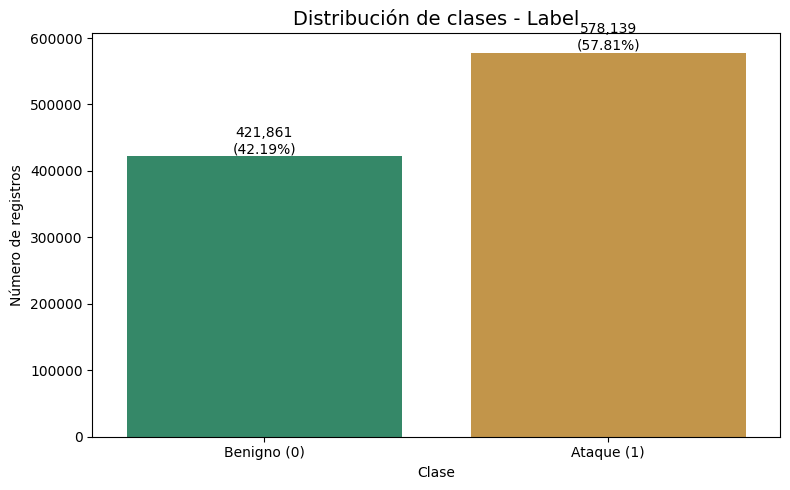

In [16]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='Label',
    hue='Label',
    palette={0: '#27966B', 1: '#D69A36'},
    legend=False
)

plt.title('Distribución de clases - Label', fontsize=14)
plt.xlabel('Clase')
plt.ylabel('Número de registros')
plt.xticks([0, 1], ['Benigno (0)', 'Ataque (1)'])

total = len(df)

for p in ax.patches:
    porcentaje = p.get_height() / total * 100
    ax.annotate(
        f'{p.get_height():,.0f}\n({porcentaje:.2f}%)',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

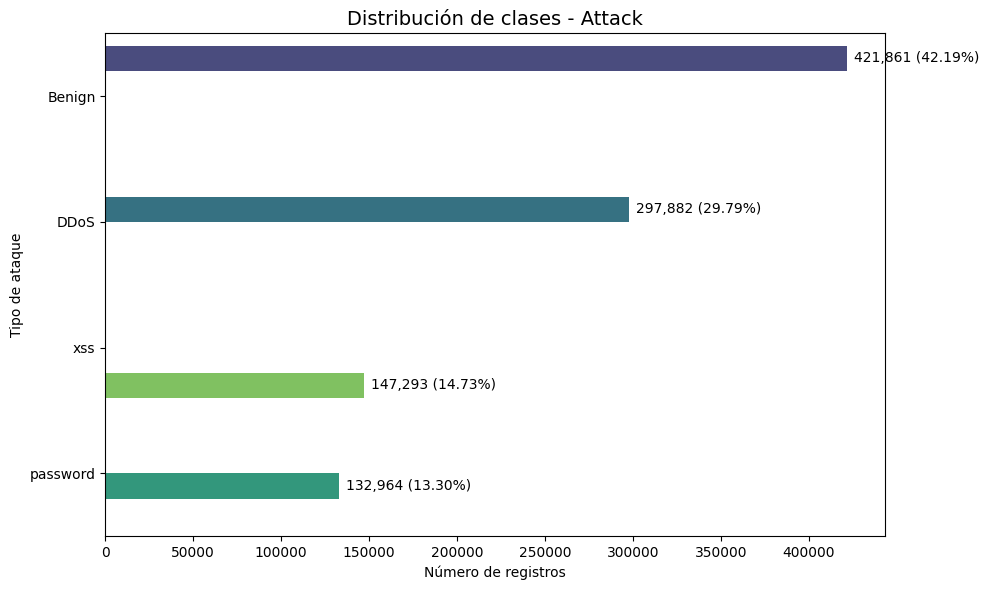

In [17]:
plt.figure(figsize=(10, 6))

orden = df['Attack'].value_counts().index

ax = sns.countplot(
    data=df,
    y='Attack',
    hue='Attack',
    order=orden,
    palette='viridis',
    legend=False
)

plt.title('Distribución de clases - Attack', fontsize=14)
plt.xlabel('Número de registros')
plt.ylabel('Tipo de ataque')

total = len(df)

for p in ax.patches:
    porcentaje = p.get_width() / total * 100
    ax.annotate(
        f'{p.get_width():,.0f} ({porcentaje:.2f}%)',
        (p.get_width(), p.get_y() + p.get_height() / 2),
        xytext=(5, 0),
        textcoords='offset points',
        va='center'
    )

plt.tight_layout()
plt.show()

La etiqueta donde se muestra un ataque con relacion al tippo de clases es consistente en el número de registros donde se muestran como benignos y como un trafico normal. Por este motivo se debe sacar estas dos variables al momento de predecir

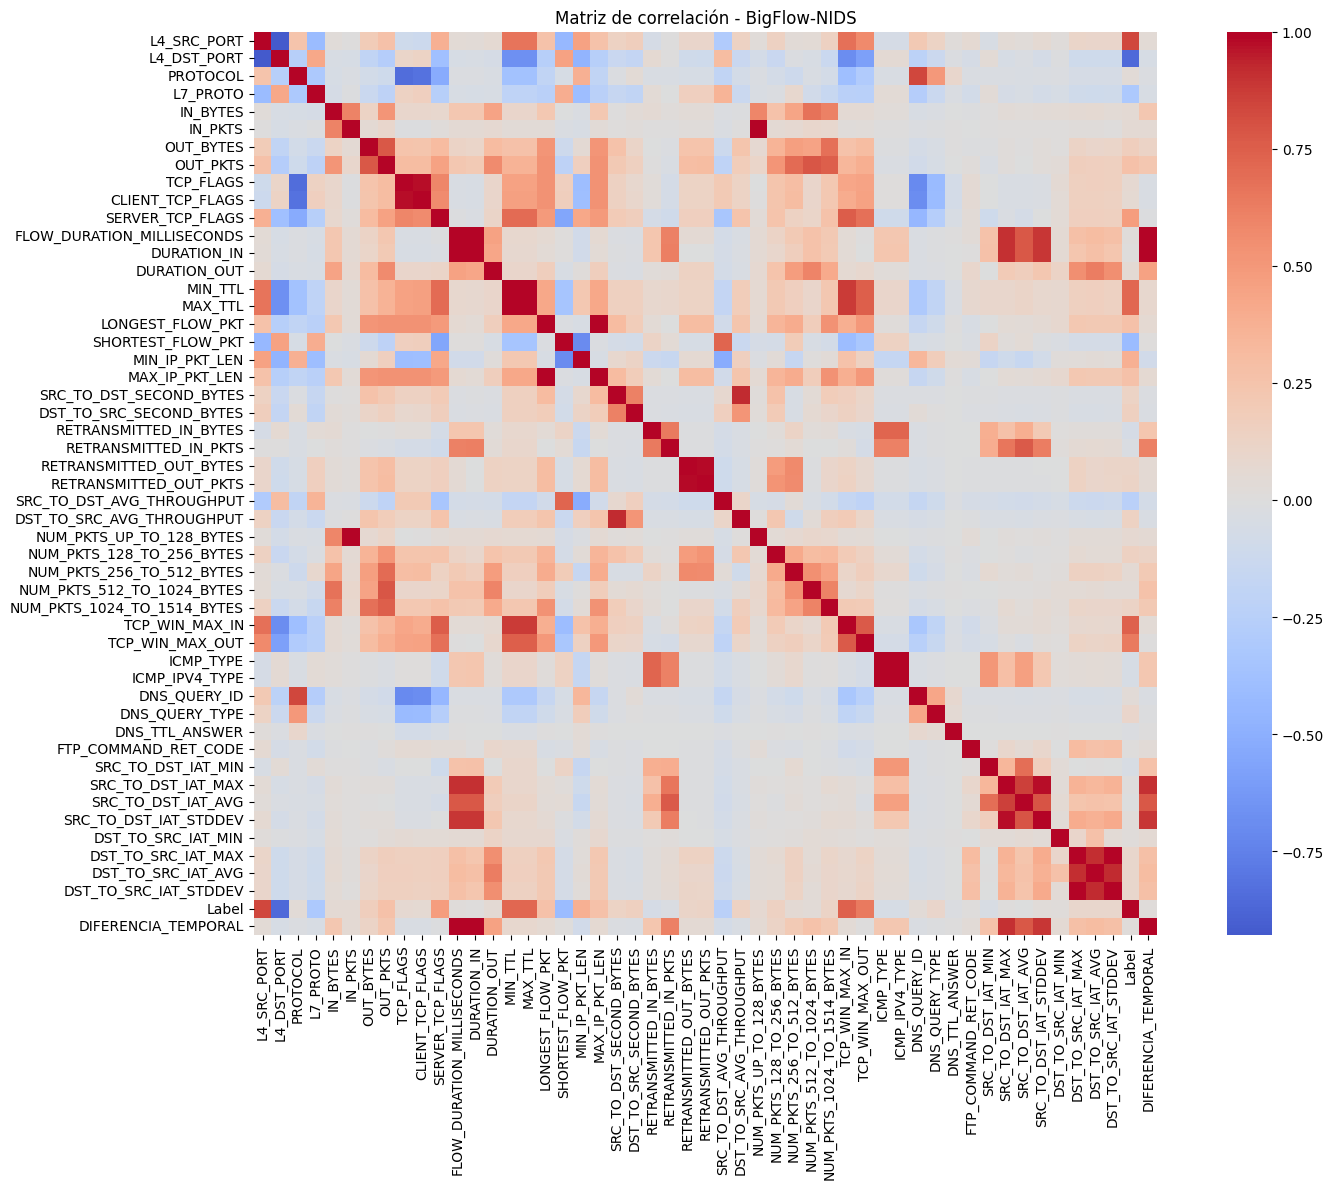

In [18]:
# Seleccionar variables numéricas
# La correlacion no necesita el millon de filas, con una muestra da igual
df_numerico = df.select_dtypes(include='number').sample(200_000, random_state=SEMILLA)

# Calcular y graficar la correlación
plt.figure(figsize=(16, 12))

sns.heatmap(
    df_numerico.corr(),
    annot=False,
    cmap='coolwarm',
    square=True,
    center=0
)

plt.title('Matriz de correlación - BigFlow-NIDS')
plt.tight_layout()
plt.show()

In [19]:
# Calcular correlación respecto a Label
correlaciones = (
    df.select_dtypes(include='number')
      .corr()['Label']
      .drop('Label')
      .sort_values(ascending=False)
)



In [20]:
# 10 variables con mayor correlación positiva
mayor_correlacion = correlaciones.head(10)

# 10 variables con menor correlación (más negativa)
menor_correlacion = correlaciones.tail(10).sort_values()

print("10 variables con mayor correlación positiva:")
display(mayor_correlacion)

print("\n10 variables con menor correlación:")
display(menor_correlacion)

10 variables con mayor correlación positiva:


L4_SRC_PORT         0.833400
TCP_WIN_MAX_IN      0.739136
MAX_TTL             0.718163
MIN_TTL             0.718163
TCP_WIN_MAX_OUT     0.638296
SERVER_TCP_FLAGS    0.477651
MIN_IP_PKT_LEN      0.374964
MAX_IP_PKT_LEN      0.261355
LONGEST_FLOW_PKT    0.261355
OUT_PKTS            0.253346
Name: Label, dtype: float64


10 variables con menor correlación:


L4_DST_PORT                 -0.854369
SHORTEST_FLOW_PKT           -0.415647
L7_PROTO                    -0.313899
SRC_TO_DST_AVG_THROUGHPUT   -0.234359
RETRANSMITTED_IN_BYTES      -0.056933
ICMP_TYPE                   -0.052844
ICMP_IPV4_TYPE              -0.052844
SRC_TO_DST_IAT_MIN          -0.044960
RETRANSMITTED_IN_PKTS       -0.028122
DNS_TTL_ANSWER              -0.020477
Name: Label, dtype: float64

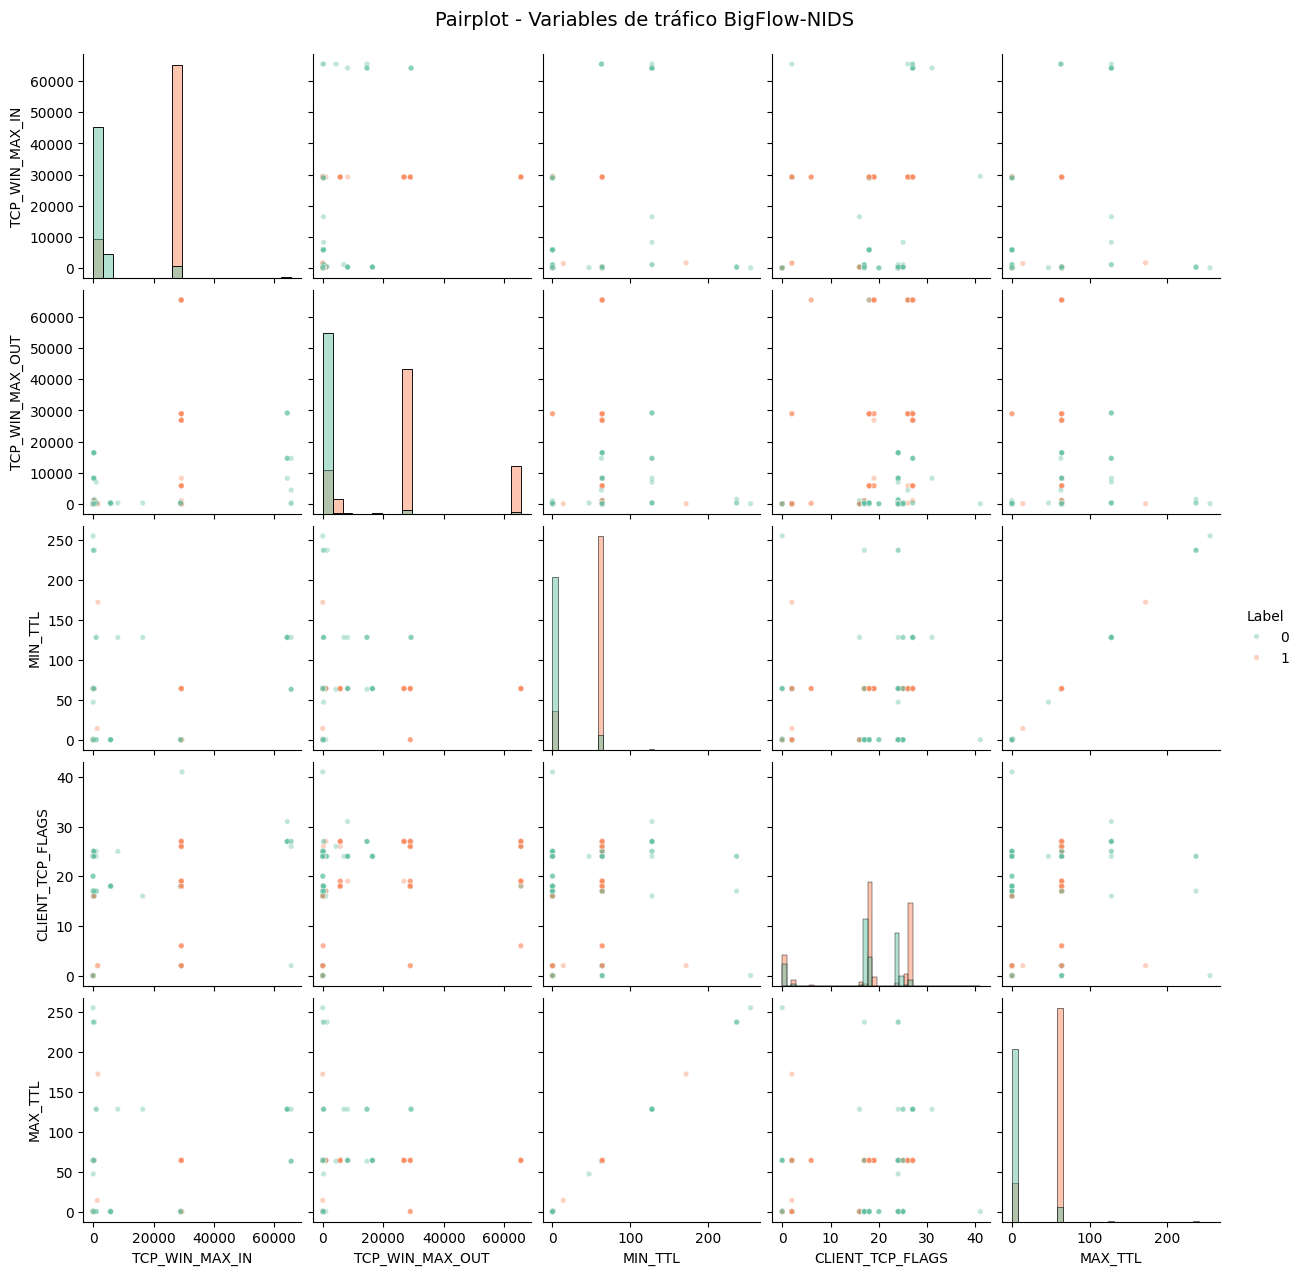

In [21]:

variables = [
    'TCP_WIN_MAX_IN',
    'TCP_WIN_MAX_OUT',
    'MIN_TTL',
    'CLIENT_TCP_FLAGS',
    'MAX_TTL',
    'Label'
]

# El pairplot con el millon de filas no termina: son 36 subgraficos de un
# millon de puntos cada uno. Se grafica sobre una muestra, que para ver la
# forma de las nubes alcanza.
df_pairplot = df[variables].dropna().sample(5000, random_state=SEMILLA)

g = sns.pairplot(
    df_pairplot,
    hue='Label',
    diag_kind='hist',
    plot_kws={'alpha': 0.4, 's': 15},
    palette='Set2'
)

g.figure.suptitle(
    'Pairplot - Variables de tráfico BigFlow-NIDS',
    y=1.02,
    fontsize=14
)

plt.show()

En el análisis exploratorio mediante el gráfico Pairplot no se observa una separación visual claramente definida entre las clases de tráfico benigno y malicioso. Por esta razón, se propone aplicar un método de selección de características basado en regularización L1 (Lasso), mediante regresión logística, con el propósito de identificar las variables más relevantes para la clasificación y reducir la dimensionalidad del conjunto de datos. Y adicionalmente balancear el dataset


In [22]:
df_original = df.copy()

In [23]:
# Eliminar columna de ataque 
df_label = df_original.drop(columns=['Attack'])

In [24]:


def generar_subsamples_maj_lasso(
    df,
    target_col,
    n_subsamples=50,
    n_muestra=5000
):
    majority_class = df[df[target_col] == 0]
    minority_class = df[df[target_col] == 1]

    for i in range(n_subsamples):

        majority_subsampled = resample(
            majority_class,
            replace=False,
            n_samples=n_muestra,
            random_state=i
        )

        minority_subsampled = resample(
            minority_class,
            replace=False,
            n_samples=n_muestra,
            random_state=i + 100
        )

        subsample = pd.concat(
            [majority_subsampled, minority_subsampled],
            ignore_index=True
        )

        subsample = subsample.sample(
            frac=1,
            random_state=i
        ).reset_index(drop=True)

        yield subsample

In [25]:
def aplicar_lasso_en_subsamples(
    subsamples,
    target_col,
    C=1.0
):
    frecuencias = {}
    total_subsamples = 0

    for i, subsample in enumerate(subsamples):

        # Separar variables predictoras y objetivo
        X = subsample.drop(
            columns=[target_col, 'Attack'],
            errors='ignore'
        )

        y = subsample[target_col]

        # Conservar variables numéricas
        X = X.select_dtypes(include='number')

        # Eliminar variables constantes
        X = X.loc[:, X.nunique() > 1]

        # Pipeline de preprocesamiento y regresión logística L1
        modelo = Pipeline([
            ('imputador', SimpleImputer(strategy='median')),
            ('escalador', StandardScaler()),
            ('lasso', LogisticRegression(
                penalty='l1',
                solver='saga',
                C=C,
                max_iter=3000,
                random_state=42
            ))
        ])

        modelo.fit(X, y)

        # Obtener coeficientes
        # coef_ es (n_clases, n_variables) cuando hay mas de dos clases, asi
        # que con coef_[0] solo se miraria la primera. Se toma el coeficiente
        # de mayor magnitud entre las clases.
        coef = modelo.named_steps['lasso'].coef_
        coeficientes = np.abs(coef).max(axis=0)

        # Identificar variables seleccionadas
        features = X.columns[
            np.abs(coeficientes) > 1e-8
        ].tolist()

        # Contabilizar selección
        for feature in features:
            frecuencias[feature] = (
                frecuencias.get(feature, 0) + 1
            )

        total_subsamples += 1

        if i < 3:
            print(
                f"Subsample {i + 1}: "
                f"{len(features)} variables seleccionadas"
            )

        del modelo, X, y, subsample

    return frecuencias, total_subsamples

In [26]:
def crear_dataset_con_lasso(
    df_original,
    subsamples,
    target_col,
    umbral=0.6,
    C=1.0
):

    print("Aplicando L1 en los subconjuntos...")

    frecuencias, total = aplicar_lasso_en_subsamples(
        subsamples,
        target_col=target_col,
        C=C
    )

    # Calcular frecuencia relativa
    frecuencia_relativa = {
        feature: count / total
        for feature, count in frecuencias.items()
    }

    # Crear tabla de frecuencias
    tabla_frecuencias = pd.DataFrame({
        'Variable': frecuencia_relativa.keys(),
        'Frecuencia': frecuencia_relativa.values()
    })

    tabla_frecuencias = tabla_frecuencias.sort_values(
        'Frecuencia',
        ascending=False
    )

    # Seleccionar variables que cumplen el umbral
    caracteristicas_seleccionadas = (
        tabla_frecuencias.loc[
            tabla_frecuencias['Frecuencia'] >= umbral,
            'Variable'
        ].tolist()
    )

    print(f"\nSubconjuntos procesados: {total}")
    print(
        f"Variables seleccionadas: "
        f"{len(caracteristicas_seleccionadas)}"
    )

    display(tabla_frecuencias)

    # Crear dataset final conservando la distribución original
    columnas_finales = caracteristicas_seleccionadas + [target_col]

    dataset_final = df_original[columnas_finales].copy()

    return (
        dataset_final,
        caracteristicas_seleccionadas,
        tabla_frecuencias
    )

In [27]:
generador = generar_subsamples_maj_lasso(
    df_label,
    n_subsamples=50,
    n_muestra=5000,
    target_col='Label'
)

In [28]:
dataset_final, features_importantes, frecuencias = crear_dataset_con_lasso(
    df_original=df_label,
    subsamples=generador,
    target_col='Label',
    umbral=0.6,
    C=0.01
)

Aplicando L1 en los subconjuntos...


Subsample 1: 17 variables seleccionadas


Subsample 2: 16 variables seleccionadas


Subsample 3: 17 variables seleccionadas



Subconjuntos procesados: 50
Variables seleccionadas: 14


,Variable,Frecuencia
0,L4_SRC_PORT,1.00
1,L4_DST_PORT,1.00
2,PROTOCOL,1.00
4,MIN_TTL,1.00
5,MAX_TTL,1.00
12,DNS_QUERY_TYPE,1.00
10,TCP_WIN_MAX_IN,1.00
11,TCP_WIN_MAX_OUT,1.00
13,DNS_TTL_ANSWER,0.88
3,OUT_BYTES,0.86


In [29]:
# Ya se saco dataset_final, df_label no se vuelve a usar. Liberar la memoria: el notebook acumula varias copias
# del millon de filas y se queda sin RAM antes de llegar al final.
del df_label
gc.collect()

print('Liberado: df_label')

Liberado: df_label


In [30]:
dataset_final

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,MIN_TTL,MAX_TTL,DNS_QUERY_TYPE,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,DNS_TTL_ANSWER,OUT_BYTES,NUM_PKTS_512_TO_1024_BYTES,FTP_COMMAND_RET_CODE,NUM_PKTS_1024_TO_1514_BYTES,RETRANSMITTED_IN_PKTS,Label
1000000,443,50910,6,0,0,0,227,229,0,52,0,0,0,0,0
1000001,49552,443,6,64,64,0,29200,28960,0,60,0,0,0,0,1
1000002,443,57546,6,0,0,0,227,0,0,0,0,0,0,0,0
1000003,54830,443,6,64,64,0,29200,28960,0,60,0,0,0,0,1
1000004,32998,443,6,64,64,0,29200,28960,0,60,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1999995,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0
1999996,57467,53,17,0,0,1,0,0,1628,81,0,0,0,0,1
1999997,45688,80,6,64,64,0,29200,65535,0,1494,1,0,0,0,1
1999998,57938,53,17,0,0,1,0,0,218,81,0,0,0,0,1


In [31]:
## revisar si aunque sea numerico no haya variables categoricas que no se hayan convertido a numerico 

resumen = pd.DataFrame({
    'Tipo': dataset_final.dtypes,
    'Valores únicos': dataset_final.nunique(),
    'Porcentaje únicos': (
        dataset_final.nunique() / len(dataset_final) * 100
    ).round(2)
})

display(resumen.sort_values('Valores únicos'))

,Tipo,Valores únicos,Porcentaje únicos
Label,int8,2,0.00
FTP_COMMAND_RET_CODE,int16,3,0.00
PROTOCOL,int8,4,0.00
RETRANSMITTED_IN_PKTS,int8,8,0.00
DNS_QUERY_TYPE,int16,10,0.00
MAX_TTL,int16,28,0.00
MIN_TTL,int16,28,0.00
NUM_PKTS_512_TO_1024_BYTES,int16,40,0.00
NUM_PKTS_1024_TO_1514_BYTES,int16,59,0.01
TCP_WIN_MAX_OUT,int32,298,0.03


In [32]:
columnas_cat = [
    'PROTOCOL',
    'DNS_QUERY_TYPE',
    'FTP_COMMAND_RET_CODE'
]

columnas_num = [
    'RETRANSMITTED_IN_PKTS',
    'MIN_TTL',
    'MAX_TTL',
    'NUM_PKTS_512_TO_1024_BYTES',
    'NUM_PKTS_1024_TO_1514_BYTES',
    'TCP_WIN_MAX_OUT',
    'TCP_WIN_MAX_IN',
    'DNS_TTL_ANSWER',
    'OUT_BYTES',
    'L4_SRC_PORT',
    'L4_DST_PORT'
]

In [33]:
encoder = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore'
)

# Ajustar encoder únicamente con las variables categóricas
encoder.fit(dataset_final[columnas_cat])


def preparar(X_part):

    # Conservar Label intacta
    y = X_part['Label'].copy()

    # Variables numéricas
    df_num = X_part[columnas_num].copy()

    # Codificar variables categóricas
    enc = encoder.transform(X_part[columnas_cat])

    nombres = encoder.get_feature_names_out(columnas_cat)

    df_enc = pd.DataFrame(
        enc,
        columns=nombres,
        index=X_part.index
    )

    # Unir variables numéricas y categóricas
    X_enc = pd.concat([df_num, df_enc], axis=1)

    # Incorporar Label sin transformarla
    X_enc['Label'] = y

    return X_enc


dataset_enc = preparar(dataset_final)

print("Dimensiones originales:", dataset_final.shape)
print("Dimensiones transformadas:", dataset_enc.shape)

Dimensiones originales: (1000000, 15)
Dimensiones transformadas: (1000000, 26)


In [34]:
# dataset_final ya quedo codificado en dataset_enc. Liberar la memoria: el notebook acumula varias copias
# del millon de filas y se queda sin RAM antes de llegar al final.
del dataset_final
gc.collect()

print('Liberado: dataset_final')

Liberado: dataset_final


In [35]:
X = dataset_enc.drop(columns=['Label'])
y = dataset_enc['Label']

# Primera partición: 85% temporal y 15% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Segunda partición: 70% train y 15% validation aproximadamente
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1764706,
    random_state=42,
    stratify=y_temp
)

In [36]:
# De aca en adelante solo se usan X_train / X_val / X_test. Liberar la memoria: el notebook acumula varias copias
# del millon de filas y se queda sin RAM antes de llegar al final.
del dataset_enc, X_temp, y_temp
gc.collect()

print('Liberado: dataset_enc, X_temp, y_temp')

Liberado: dataset_enc, X_temp, y_temp


In [37]:
print('═══ Distribución de clases: Label ═══')

print(f'Dataset completo: {y.mean():.4f}')
print()
print('Con estratificación:')

print(f'Train: {y_train.mean():.4f}')
print(f'Validation: {y_val.mean():.4f}')
print(f'Test: {y_test.mean():.4f}')

═══ Distribución de clases: Label ═══
Dataset completo: 0.5781

Con estratificación:
Train: 0.5781
Validation: 0.5781
Test: 0.5781


In [38]:
distribucion = pd.DataFrame({
    'Dataset completo': y.value_counts(normalize=True),
    'Train': y_train.value_counts(normalize=True),
    'Validation': y_val.value_counts(normalize=True),
    'Test': y_test.value_counts(normalize=True)
}) * 100

display(distribucion.round(2))

,Dataset completo,Train,Validation,Test
Label,,,,
1,57.81,57.81,57.81,57.81
0,42.19,42.19,42.19,42.19


In [39]:

# Estandarización
escalador = StandardScaler()

X_train_scaled = escalador.fit_transform(X_train)
X_val_scaled = escalador.transform(X_val)
X_test_scaled = escalador.transform(X_test)

# PCA conservando el 95% de la varianza
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print('Variables originales:', X_train.shape[1])
print('Componentes PCA:', pca.n_components_)
print(
    'Varianza explicada:',
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    '%'
)

Variables originales: 25
Componentes PCA: 16
Varianza explicada: 95.37 %


In [40]:
# Los escalados solo servian para calcular el PCA. Liberar la memoria: el notebook acumula varias copias
# del millon de filas y se queda sin RAM antes de llegar al final.
del X_train_scaled, X_val_scaled, X_test_scaled
gc.collect()

print('Liberado: X_train_scaled, X_val_scaled, X_test_scaled')

Liberado: X_train_scaled, X_val_scaled, X_test_scaled


In [41]:
X_test_pca


array([[-2.35149314e+00, -1.87485735e+00,  2.78585579e-01, ...,
        -8.91552536e-05,  2.22765735e-02,  1.06074258e-01],
       [ 1.97931027e+00,  1.97167218e-01, -7.15497935e-01, ...,
        -2.31794462e-04,  6.39674688e-04, -3.20287221e-01],
       [-2.96943391e+00,  4.29626136e+00,  1.71538639e-01, ...,
        -5.15894494e-03, -1.11195491e-01,  3.98287540e-02],
       ...,
       [-2.95475021e+00,  4.31463605e+00,  1.66779320e-01, ...,
        -5.17020956e-03, -1.15916808e-01,  3.73326803e-02],
       [ 2.75253172e+00,  3.94371962e-01, -6.00834217e-01, ...,
        -2.86617535e-04,  5.85847142e-03,  1.19046382e-01],
       [ 2.04846687e+00,  2.86406097e-01, -7.37590043e-01, ...,
        -2.82357805e-04, -2.07596156e-03, -3.32213450e-01]],
      shape=(150000, 16))

In [42]:
tabla_componentes = pd.DataFrame({
    'Componente': [
        f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))
    ],
    'Varianza individual (%)': pca.explained_variance_ratio_ * 100,
    'Varianza acumulada (%)': np.cumsum(
        pca.explained_variance_ratio_
    ) * 100
})

display(tabla_componentes.round(3))

,Componente,Varianza individual (%),Varianza acumulada (%)
0,PC1,21.452,21.452
1,PC2,13.358,34.810
2,PC3,7.767,42.577
3,PC4,5.318,47.895
4,PC5,4.380,52.274
5,PC6,4.334,56.608
6,PC7,4.222,60.830
7,PC8,4.182,65.011
8,PC9,4.176,69.188
9,PC10,4.169,73.357


In [43]:
X_train_pca


array([[-3.06508577e+00,  4.03155281e+00,  1.85293954e-01, ...,
        -1.24229743e-02,  1.07504406e-01,  6.13239393e-02],
       [ 2.00506045e+00,  2.30380071e-01, -7.23703101e-01, ...,
        -2.52680929e-04, -3.47140160e-04, -3.24717317e-01],
       [ 2.29690770e+00,  3.14122690e-02,  1.29084791e+00, ...,
        -1.45514267e-05,  1.26099915e-03,  1.38046371e+00],
       ...,
       [ 1.89960982e+00,  6.43728643e-02, -5.96009750e-01, ...,
        -1.49065226e-04,  4.40976202e-03, -1.66322232e-01],
       [-2.93456413e+00,  4.34972900e+00,  1.54526855e-01, ...,
        -5.19536608e-03, -6.60119095e-02,  2.33578460e-02],
       [-2.11032187e+00, -1.56170949e+00,  1.98836167e-01, ...,
         3.28979298e-06,  9.62943463e-03,  6.31018342e-02]],
      shape=(699999, 16))

### REGRESION LOGISTICA

In [44]:
# ── Entrenar Regresión Logística ─────────────────────────────────────────────
# max_iter=1000 → número máximo de iteraciones del optimizador
# C=1.0        → inverso de la regularización (mayor C = menos regularización)
# solver='lbfgs' → algoritmo de optimización (bueno para datasets medianos)

modelo_lr = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', random_state=42)
modelo_lr.fit(X_train_pca, y_train)

# Predicciones: clase (0 ó 1) y probabilidades
y_pred_val  = modelo_lr.predict(X_val_pca)          # Clase predicha
y_prob_val  = modelo_lr.predict_proba(X_val_pca)[:, 1]  # P(Ataque=1)

print('Primeras 10 predicciones:')
print('  Clase real:    ', y_val.values[:10])
print('  Clase predicha:', y_pred_val[:10])
print('  P(Ataque=1):    ', y_prob_val[:10].round(3))

Primeras 10 predicciones:
  Clase real:     [1 0 1 1 1 0 0 0 1 1]
  Clase predicha: [1 1 0 1 1 1 0 0 1 1]
  P(Ataque=1):     [0.991 0.511 0.487 0.996 0.992 0.618 0.016 0.011 0.993 0.986]


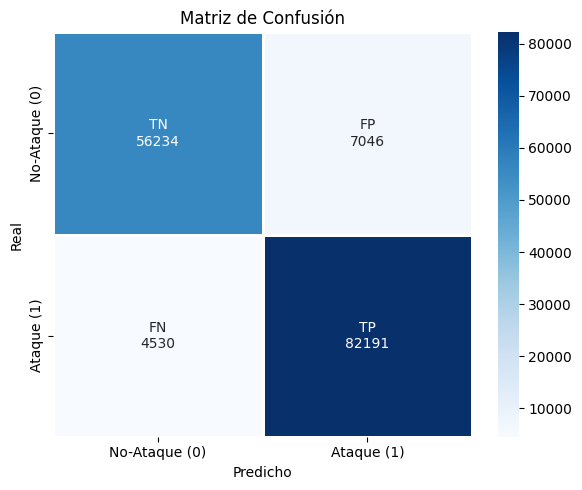

In [45]:
def graficar_matriz_confusion(y_real, y_pred, titulo='Matriz de Confusión'):
    cm = confusion_matrix(y_real, y_pred)
    tn, fp, fn, tp = cm.ravel()

    etiquetas = np.array([
        [f'TN\n{tn}', f'FP\n{fp}'],
        [f'FN\n{fn}', f'TP\n{tp}']
    ])

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=etiquetas, fmt='', cmap='Blues',
                xticklabels=['No-Ataque (0)', 'Ataque (1)'],
                yticklabels=['No-Ataque (0)', 'Ataque (1)'],
                linewidths=1)
    plt.title(titulo)
    plt.xlabel('Predicho')
    plt.ylabel('Real')
    plt.tight_layout()
    plt.show()
    return tn, fp, fn, tp

tn, fp, fn, tp = graficar_matriz_confusion(y_val, y_pred_val)

In [46]:
# Calcular todas las métricas manualmente desde la matriz de confusión
accuracy    = (tp + tn) / (tp + tn + fp + fn)
precision   = tp / (tp + fp) if (tp + fp) > 0 else 0
recall      = tp / (tp + fn) if (tp + fn) > 0 else 0  # también llamado Sensibilidad
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
f1          = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
roc_auc     = roc_auc_score(y_val, y_prob_val)

print('═══ MÉTRICAS DE CLASIFICACIÓN (Validation) ══════════════')
print(f'  Accuracy    (exactitud global):    {accuracy:.4f}')
print(f'  Precision   (de mis alertas, % OK):{precision:.4f}')
print(f'  Recall      (% ataques detectados): {recall:.4f}')
print(f'  Specificity (% no-ataques OK):      {specificity:.4f}')
print(f'  F1-Score    (balance P y R):       {f1:.4f}')
print(f'  ROC-AUC     (discriminación):      {roc_auc:.4f}')
print()
print('Verificación con sklearn:')
print(f'  accuracy_score:   {accuracy_score(y_val, y_pred_val):.4f}')
print(f'  precision_score:  {precision_score(y_val, y_pred_val):.4f}')
print(f'  recall_score:     {recall_score(y_val, y_pred_val):.4f}')
print(f'  f1_score:         {f1_score(y_val, y_pred_val):.4f}')

═══ MÉTRICAS DE CLASIFICACIÓN (Validation) ══════════════
  Accuracy    (exactitud global):    0.9228
  Precision   (de mis alertas, % OK):0.9210
  Recall      (% ataques detectados): 0.9478
  Specificity (% no-ataques OK):      0.8887
  F1-Score    (balance P y R):       0.9342
  ROC-AUC     (discriminación):      0.9764

Verificación con sklearn:


  accuracy_score:   0.9228
  precision_score:  0.9210
  recall_score:     0.9478
  f1_score:         0.9342


In [47]:
# Reporte completo de sklearn (incluye métricas para ambas clases)
print('─── Classification Report ──────────────────────────────────')
print(classification_report(y_val, y_pred_val, target_names=['No-Ataque (0)', 'Ataque (1)']))
print('Nota: support = número de muestras reales en cada clase')

─── Classification Report ──────────────────────────────────


               precision    recall  f1-score   support

No-Ataque (0)       0.93      0.89      0.91     63280
   Ataque (1)       0.92      0.95      0.93     86721

     accuracy                           0.92    150001
    macro avg       0.92      0.92      0.92    150001
 weighted avg       0.92      0.92      0.92    150001

Nota: support = número de muestras reales en cada clase


#### curva ROC

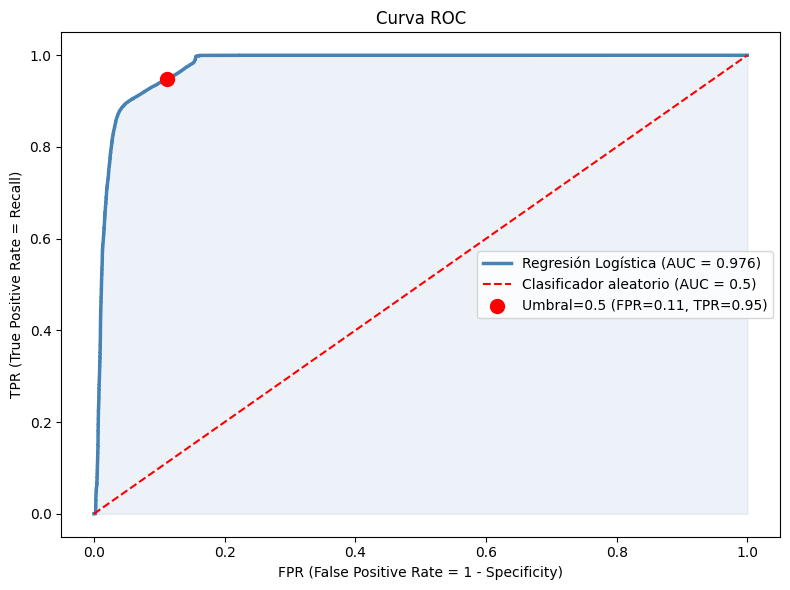

In [48]:
fpr, tpr, umbrales = roc_curve(y_val, y_prob_val)
auc = roc_auc_score(y_val, y_prob_val)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='steelblue', linewidth=2.5,
         label=f'Regresión Logística (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'r--', linewidth=1.5, label='Clasificador aleatorio (AUC = 0.5)')
plt.fill_between(fpr, tpr, alpha=0.1, color='steelblue')

# Marcar el umbral 0.5
idx_05 = np.argmin(np.abs(umbrales - 0.5))
plt.scatter(fpr[idx_05], tpr[idx_05], color='red', s=100, zorder=5,
            label=f'Umbral=0.5 (FPR={fpr[idx_05]:.2f}, TPR={tpr[idx_05]:.2f})')

plt.xlabel('FPR (False Positive Rate = 1 - Specificity)')
plt.ylabel('TPR (True Positive Rate = Recall)')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.show()

#### trade-off recall

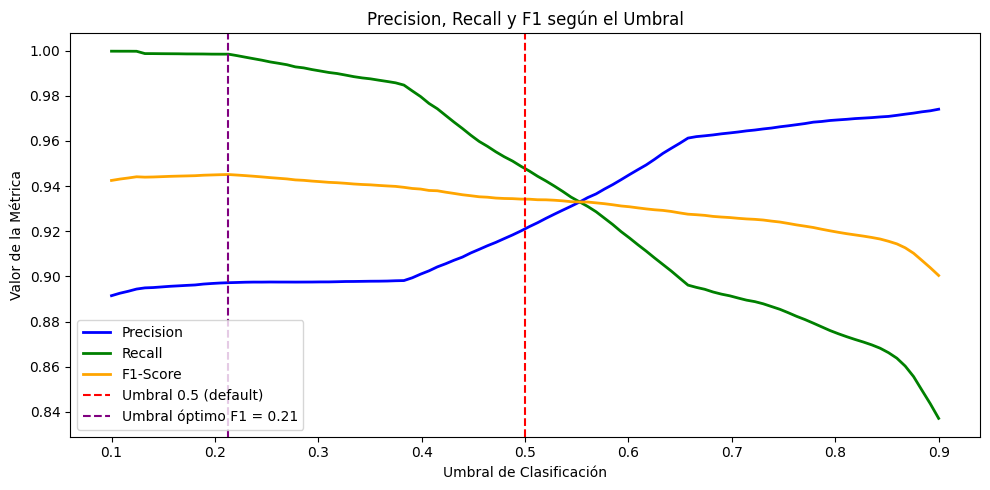

Umbral óptimo por F1: 0.21
  F1 con umbral 0.5:    0.9342
  F1 con umbral óptimo: 0.9451


In [49]:
# Cómo cambian Precision y Recall al variar el umbral
umbrales_rango = np.linspace(0.1, 0.9, 100)
precisiones, recalls, f1s = [], [], []

for u in umbrales_rango:
    y_pred_u = (y_prob_val >= u).astype(int)
    precisiones.append(precision_score(y_val, y_pred_u, zero_division=0))
    recalls.append(recall_score(y_val, y_pred_u, zero_division=0))
    f1s.append(f1_score(y_val, y_pred_u, zero_division=0))

# Umbral óptimo según F1
idx_opt = np.argmax(f1s)
umbral_opt = umbrales_rango[idx_opt]

plt.figure(figsize=(10, 5))
plt.plot(umbrales_rango, precisiones, label='Precision', color='blue',   linewidth=2)
plt.plot(umbrales_rango, recalls,    label='Recall',    color='green',   linewidth=2)
plt.plot(umbrales_rango, f1s,        label='F1-Score',  color='orange',  linewidth=2)
plt.axvline(0.5,         color='red',   linestyle='--', linewidth=1.5, label='Umbral 0.5 (default)')
plt.axvline(umbral_opt,  color='purple',linestyle='--', linewidth=1.5,
            label=f'Umbral óptimo F1 = {umbral_opt:.2f}')
plt.xlabel('Umbral de Clasificación')
plt.ylabel('Valor de la Métrica')
plt.title('Precision, Recall y F1 según el Umbral')
plt.legend()
plt.tight_layout()
plt.show()

print(f'Umbral óptimo por F1: {umbral_opt:.2f}')
print(f'  F1 con umbral 0.5:    {f1_score(y_val, (y_prob_val>=0.5).astype(int)):.4f}')
print(f'  F1 con umbral óptimo: {f1s[idx_opt]:.4f}')

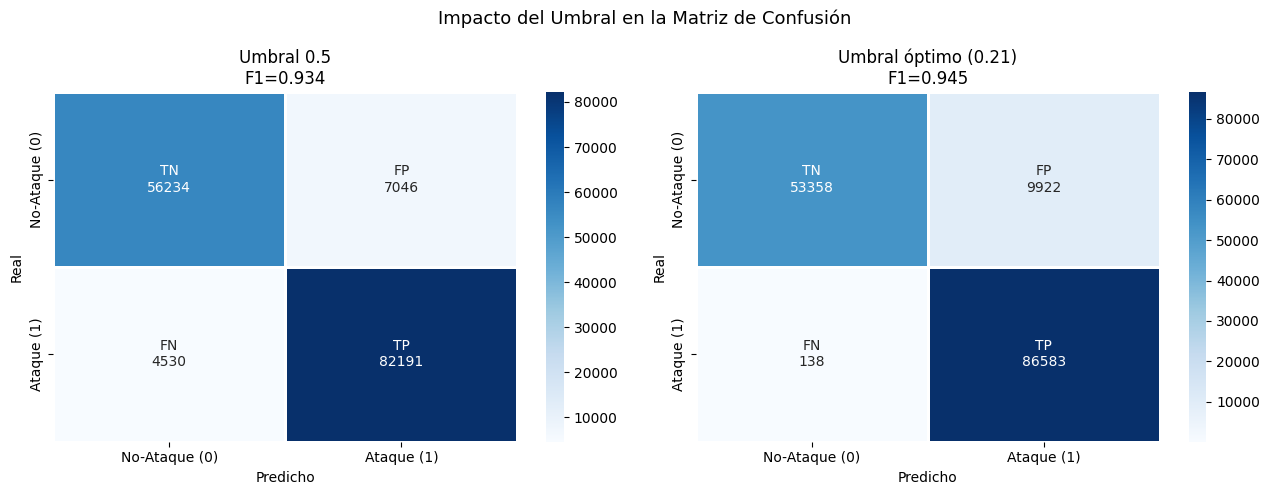

In [50]:
# Comparar umbral 0.5 vs umbral óptimo
y_pred_opt = (y_prob_val >= umbral_opt).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, y_p, titulo in zip(
    axes,
    [y_pred_val, y_pred_opt],
    [f'Umbral 0.5\nF1={f1_score(y_val,y_pred_val):.3f}',
     f'Umbral óptimo ({umbral_opt:.2f})\nF1={f1_score(y_val,y_pred_opt):.3f}']
):
    cm = confusion_matrix(y_val, y_p)
    tn_i, fp_i, fn_i, tp_i = cm.ravel()
    etiq = np.array([[f'TN\n{tn_i}', f'FP\n{fp_i}'], [f'FN\n{fn_i}', f'TP\n{tp_i}']])
    sns.heatmap(cm, annot=etiq, fmt='', cmap='Blues', ax=ax,
                xticklabels=['No-Ataque (0)', 'Ataque (1)'],
                yticklabels=['No-Ataque (0)', 'Ataque (1)'], linewidths=1)
    ax.set_title(titulo)
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')

plt.suptitle('Impacto del Umbral en la Matriz de Confusión', fontsize=13)
plt.tight_layout()
plt.show()

═══ EVALUACIÓN FINAL EN TEST ════════════════════════════
               precision    recall  f1-score   support

No-Ataque (0)       1.00      0.85      0.92     63279
   Ataque (1)       0.90      1.00      0.95     86721

     accuracy                           0.94    150000
    macro avg       0.95      0.92      0.93    150000
 weighted avg       0.94      0.94      0.93    150000

  ROC-AUC (Test): 0.9763


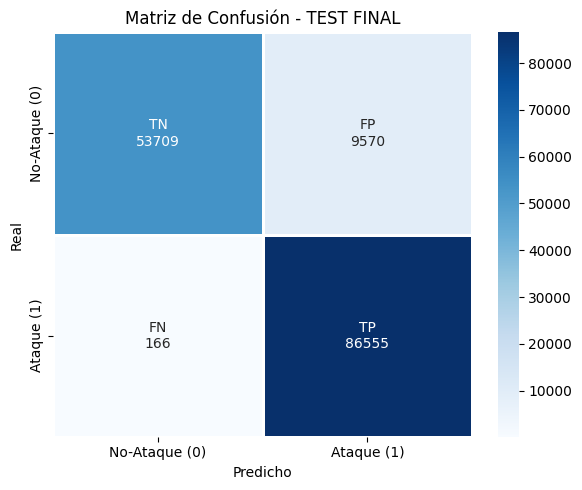

(np.int64(53709), np.int64(9570), np.int64(166), np.int64(86555))

In [51]:
# Predicciones en Test con el umbral óptimo
y_prob_test = modelo_lr.predict_proba(X_test_pca)[:, 1]
y_pred_test = (y_prob_test >= umbral_opt).astype(int)

print('═══ EVALUACIÓN FINAL EN TEST ════════════════════════════')
print(classification_report(y_test, y_pred_test, target_names=['No-Ataque (0)', 'Ataque (1)']))

auc_test = roc_auc_score(y_test, y_prob_test)
print(f'  ROC-AUC (Test): {auc_test:.4f}')

graficar_matriz_confusion(y_test, y_pred_test, 'Matriz de Confusión - TEST FINAL')

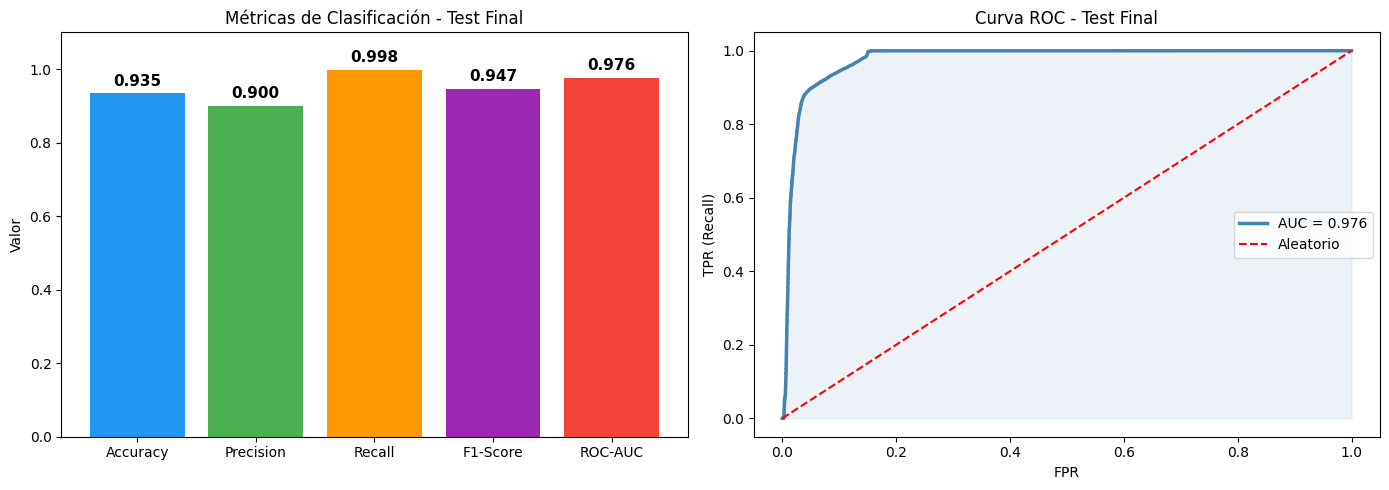

In [52]:
# Dashboard resumen
metricas_finales = {
    'Accuracy':    accuracy_score(y_test, y_pred_test),
    'Precision':   precision_score(y_test, y_pred_test),
    'Recall':      recall_score(y_test, y_pred_test),
    'F1-Score':    f1_score(y_test, y_pred_test),
    'ROC-AUC':     roc_auc_score(y_test, y_prob_test)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras de métricas
colores_bar = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#F44336']
bars = axes[0].bar(metricas_finales.keys(), metricas_finales.values(), color=colores_bar)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Métricas de Clasificación - Test Final')
axes[0].set_ylabel('Valor')
for bar, val in zip(bars, metricas_finales.values()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.3f}', ha='center', fontsize=11, fontweight='bold')

# Curva ROC en test
fpr_t, tpr_t, _ = roc_curve(y_test, y_prob_test)
axes[1].plot(fpr_t, tpr_t, color='steelblue', linewidth=2.5,
             label=f'AUC = {auc_test:.3f}')
axes[1].plot([0,1],[0,1],'r--', linewidth=1.5, label='Aleatorio')
axes[1].fill_between(fpr_t, tpr_t, alpha=0.1, color='steelblue')
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR (Recall)')
axes[1].set_title('Curva ROC - Test Final')
axes[1].legend()

plt.tight_layout()
plt.show()

In [53]:


# LogisticRegressionCV automáticamente ajusta C con CV
lr_cv = LogisticRegressionCV(
    penalty='l2',
    scoring='roc_auc',
    solver='lbfgs',
    Cs=np.logspace(-4, 4, 20),
    cv=5,
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr_cv.fit(X_train_pca, y_train)

print('Resultados de LogisticRegressionCV:')
print(f'Mejor C: {lr_cv.C_[0]:.6f}')
print(f'AUC CV promedio: {lr_cv.scores_[1].mean():.4f}')

y_pred_lr = lr_cv.predict_proba(X_test_pca)[:, 1]
print(f'Predicciones de test - Mín: {y_pred_lr.min():.4f}, Máx: {y_pred_lr.max():.4f}')

Resultados de LogisticRegressionCV:
Mejor C: 0.615848
AUC CV promedio: 0.9765
Predicciones de test - Mín: 0.0000, Máx: 0.9999


In [54]:
# Se acabo el camino binario: el PCA ya no se usa mas. Liberar la memoria: el notebook acumula varias copias
# del millon de filas y se queda sin RAM antes de llegar al final.
del X_train_pca, X_val_pca, X_test_pca
gc.collect()

print('Liberado: X_train_pca, X_val_pca, X_test_pca')

Liberado: X_train_pca, X_val_pca, X_test_pca


#### Random Forest

In [55]:
# La grilla completa sobre las 700.000 filas de train no termina en un tiempo
# razonable, asi que la busqueda se hace sobre una submuestra estratificada y
# el modelo ganador se reentrena despues con todo el train.
idx_grid = (
    pd.Series(y_train)
    .groupby(y_train.values, observed=True)
    .sample(n=8000, random_state=SEMILLA, replace=True)
    .index.unique()
)

X_grid = X_train.loc[idx_grid]
y_grid = y_train.loc[idx_grid]

print("Submuestra para la busqueda:", X_grid.shape)

rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_leaf': [2, 4, 8]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

rf_grid.fit(X_grid, y_grid)

print('Resultados de Random Forest:')
print(f'Best parameters: {rf_grid.best_params_}')
print(f'Best CV AUC: {rf_grid.best_score_:.4f}')

y_pred_rf = rf_grid.predict_proba(X_test)[:, 1]
print(f'Test predictions - Min: {y_pred_rf.min():.4f}, Max: {y_pred_rf.max():.4f}')

Submuestra para la busqueda: (15812, 25)


Resultados de Random Forest:
Best parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV AUC: 0.9929


Test predictions - Min: 0.0000, Max: 0.9978


#### gradie Boosting con CV

In [56]:
# La grilla completa sobre las 700.000 filas de train no termina en un tiempo
# razonable, asi que la busqueda se hace sobre una submuestra estratificada y
# el modelo ganador se reentrena despues con todo el train.
idx_grid = (
    pd.Series(y_train)
    .groupby(y_train.values, observed=True)
    .sample(n=8000, random_state=SEMILLA, replace=True)
    .index.unique()
)

X_grid = X_train.loc[idx_grid]
y_grid = y_train.loc[idx_grid]

print("Submuestra para la busqueda:", X_grid.shape)

from sklearn.ensemble import GradientBoostingClassifier

gbm_params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7]
}

gbm_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid=gbm_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

gbm_grid.fit(X_grid, y_grid)

print('Resultados de Gradient Boosting:')
print(f'Best parameters: {gbm_grid.best_params_}')
print(f'Best CV AUC: {gbm_grid.best_score_:.4f}')

y_pred_gbm = gbm_grid.predict_proba(X_test)[:, 1]
print(f'Test predictions - Min: {y_pred_gbm.min():.4f}, Max: {y_pred_gbm.max():.4f}')

Submuestra para la busqueda: (15812, 25)


Resultados de Gradient Boosting:
Best parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Best CV AUC: 0.9927


Test predictions - Min: 0.0002, Max: 0.9969


## REGRESION LOGISTICA MULTICLASE

In [57]:
## EN ESTE CASO VAMOS A IDENTIFICAR EL TIPO DE ATAQUE

In [58]:
# Eliminar columna de label 
df_ataque = df_original.drop(columns=['Label'])

In [59]:
def generar_subsamples_multiclase(
    df,
    target_col,
    n_subsamples=50,
    n_muestra=1000
):
    clases = df[target_col].dropna().unique()

    for i in range(n_subsamples):
        muestras = []

        for clase in clases:
            datos_clase = df[df[target_col] == clase]

            muestra = resample(
                datos_clase,
                replace=len(datos_clase) < n_muestra,
                n_samples=n_muestra,
                random_state=i + 100
            )

            muestras.append(muestra)

        subsample = pd.concat(muestras, ignore_index=True)
        subsample = subsample.sample(
            frac=1,
            random_state=i
        ).reset_index(drop=True)

        yield subsample

In [60]:
generador_mc = generar_subsamples_multiclase(
    df_ataque,
    n_subsamples=50,
    n_muestra=5000,
    target_col='Attack'
)

In [61]:
# Esta celda se demora unos 36 minutos: son 50 regresiones L1 con saga. Como
# se tuvo que reintentar la corrida varias veces, se guarda el resultado y en
# las siguientes se lee del disco. Para recalcularlo, borrar el archivo.
RUTA_LASSO = os.path.join(CARPETA_DATOS, 'lasso_multiclase.parquet')

if os.path.exists(RUTA_LASSO):
    dataset_final_ataque = pd.read_parquet(RUTA_LASSO)
    features_importantes = [
        c for c in dataset_final_ataque.columns if c != 'Attack'
    ]
    print('Leido del disco:', RUTA_LASSO)
    print('Variables seleccionadas:', len(features_importantes))
else:
    dataset_final_ataque, features_importantes, frecuencias = crear_dataset_con_lasso(
        df_original=df_ataque,
        subsamples=generador_mc,
        target_col='Attack',
        umbral=0.6,
        C=0.01
    )

    dataset_final_ataque.to_parquet(RUTA_LASSO, index=False)
    print('Guardado en', RUTA_LASSO, 'para no repetirlo')

Leido del disco: data\lasso_multiclase.parquet
Variables seleccionadas: 34


In [62]:
# El Lasso multiclase ya termino, sobran las copias del millon de filas. Liberar la memoria: el notebook acumula varias copias
# del millon de filas y se queda sin RAM antes de llegar al final.
del df_ataque, df_original
gc.collect()

print('Liberado: df_ataque, df_original')

Liberado: df_ataque, df_original


In [63]:
dataset_final_ataque

,L4_DST_PORT,PROTOCOL,MAX_IP_PKT_LEN,L7_PROTO,IN_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,MAX_TTL,SRC_TO_DST_SECOND_BYTES,MIN_TTL,MIN_IP_PKT_LEN,LONGEST_FLOW_PKT,TCP_WIN_MAX_IN,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,RETRANSMITTED_OUT_PKTS,FTP_COMMAND_RET_CODE,DNS_QUERY_TYPE,TCP_WIN_MAX_OUT,SRC_TO_DST_IAT_AVG,NUM_PKTS_512_TO_1024_BYTES,L4_SRC_PORT,DST_TO_SRC_AVG_THROUGHPUT,SRC_TO_DST_AVG_THROUGHPUT,SRC_TO_DST_IAT_MAX,DST_TO_SRC_SECOND_BYTES,SERVER_TCP_FLAGS,RETRANSMITTED_OUT_BYTES,DNS_TTL_ANSWER,NUM_PKTS_UP_TO_128_BYTES,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_MIN,Attack
0,50910,6,52,91.0,52,1,1,17,17,0,0,0,52,52,227,0,0,0,0,0,229,0,0,443,416000,416000,0,0,16,0,0,2,0,0,Benign
1,443,6,60,91.0,112,2,1,18,18,64,0,64,52,60,29200,0,0,0,0,0,28960,0,0,49552,480000,896000,0,1,18,0,0,3,0,0,DDoS
2,57546,6,52,91.0,52,1,0,17,17,0,0,0,0,52,227,0,0,0,0,0,0,0,0,443,0,416000,0,0,0,0,0,1,0,0,Benign
3,443,6,60,91.0,112,2,1,18,18,64,0,64,52,60,29200,0,0,0,0,0,28960,0,0,54830,480000,896000,0,1,18,0,0,3,0,0,DDoS
4,443,6,60,91.0,112,2,1,18,18,64,1,64,52,60,29200,0,0,0,0,0,28960,48,0,32998,9795,18285,48,2,18,0,0,3,0,0,DDoS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,0,2,32,82.0,32,1,0,0,0,0,0,0,0,32,0,0,0,0,0,0,0,0,0,0,0,256000,0,0,0,0,0,1,0,0,Benign
999996,53,17,81,5.0,65,1,1,0,0,0,9,0,65,81,0,0,0,0,0,1,0,0,0,57467,64800,52000,0,7,0,0,1628,2,0,0,xss
999997,80,6,923,7.0,656,6,5,27,27,64,99,64,40,923,29200,0,2,0,0,0,65535,3,1,45688,747000,328000,15,43,27,0,0,8,15,0,xss
999998,53,17,81,5.0,65,1,1,0,0,0,11,0,65,81,0,0,0,0,0,1,0,0,0,57938,81000,65000,0,9,0,0,218,2,0,0,xss


In [64]:

resumen = pd.DataFrame({
    'Tipo': dataset_final_ataque.dtypes,
    'Valores únicos': dataset_final_ataque.nunique(),
    'Porcentaje únicos': (
        dataset_final_ataque.nunique() / len(dataset_final_ataque) * 100
    ).round(2)
})

display(resumen.sort_values('Valores únicos'))

,Tipo,Valores únicos,Porcentaje únicos
FTP_COMMAND_RET_CODE,int16,3,0.00
PROTOCOL,int8,4,0.00
Attack,category,4,0.00
RETRANSMITTED_OUT_PKTS,int8,8,0.00
DNS_QUERY_TYPE,int16,10,0.00
SERVER_TCP_FLAGS,int8,19,0.00
CLIENT_TCP_FLAGS,int8,21,0.00
TCP_FLAGS,int8,21,0.00
L7_PROTO,float32,25,0.00
MAX_TTL,int16,28,0.00


In [65]:
columnas_cat = [
    'SERVER_TCP_FLAGS',
    'FTP_COMMAND_RET_CODE'
]

columnas_num = [
    'NUM_PKTS_512_TO_1024_BYTES',
    'DNS_TTL_ANSWER',
    'L4_SRC_PORT',
    'L4_DST_PORT'
]

In [66]:
encoder = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore'
)

# Ajustar encoder únicamente con las variables categóricas
encoder.fit(dataset_final_ataque[columnas_cat])


def preparar(X_part):

    # Conservar Label intacta
    y = X_part['Attack'].copy()

    # Variables numéricas
    df_num = X_part[columnas_num].copy()

    # Codificar variables categóricas
    enc = encoder.transform(X_part[columnas_cat])

    nombres = encoder.get_feature_names_out(columnas_cat)

    df_enc = pd.DataFrame(
        enc,
        columns=nombres,
        index=X_part.index
    )

    # Unir variables numéricas y categóricas
    X_enc = pd.concat([df_num, df_enc], axis=1)

    # Incorporar Label sin transformarla
    X_enc['Attack'] = y

    return X_enc


dataset_final_ataque_enc = preparar(dataset_final_ataque)

print("Dimensiones originales:", dataset_final_ataque.shape)
print("Dimensiones transformadas:", dataset_final_ataque_enc.shape)

Dimensiones originales: (1000000, 35)
Dimensiones transformadas: (1000000, 25)


In [67]:
dataset_final_ataque_enc

,NUM_PKTS_512_TO_1024_BYTES,DNS_TTL_ANSWER,L4_SRC_PORT,L4_DST_PORT,SERVER_TCP_FLAGS_2,SERVER_TCP_FLAGS_4,SERVER_TCP_FLAGS_6,SERVER_TCP_FLAGS_16,SERVER_TCP_FLAGS_17,SERVER_TCP_FLAGS_18,SERVER_TCP_FLAGS_19,SERVER_TCP_FLAGS_20,SERVER_TCP_FLAGS_21,SERVER_TCP_FLAGS_22,SERVER_TCP_FLAGS_23,SERVER_TCP_FLAGS_24,SERVER_TCP_FLAGS_25,SERVER_TCP_FLAGS_26,SERVER_TCP_FLAGS_27,SERVER_TCP_FLAGS_28,SERVER_TCP_FLAGS_30,SERVER_TCP_FLAGS_31,FTP_COMMAND_RET_CODE_331,FTP_COMMAND_RET_CODE_530,Attack
0,0,0,443,50910,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
1,0,0,49552,443,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS
2,0,0,443,57546,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
3,0,0,54830,443,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS
4,0,0,32998,443,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
999996,0,1628,57467,53,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,xss
999997,1,0,45688,80,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,xss
999998,0,218,57938,53,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,xss


In [68]:
X = dataset_final_ataque_enc.drop(columns=['Attack'])
y = dataset_final_ataque_enc['Attack']

print("Dimensiones X:", X.shape)
print("Dimensiones y:", y.shape)

Dimensiones X: (1000000, 24)
Dimensiones y: (1000000,)


In [69]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1764706,
    random_state=42,
    stratify=y_temp
)

# Escalar antes de entrenar. Sin esto lbfgs no alcanza a converger en 1000
# iteraciones (sale un ConvergenceWarning) y la accuracy queda por debajo de lo
# que el modelo puede dar: en la misma tabla hay bytes, milisegundos y numeros
# de puerto, que son escalas completamente distintas.
escalador_ataque = StandardScaler()

X_train = escalador_ataque.fit_transform(X_train)
X_val = escalador_ataque.transform(X_val)
X_test = escalador_ataque.transform(X_test)

print("Escalado aplicado. Train:", X_train.shape)

Escalado aplicado. Train: (699999, 24)


In [70]:
print('Entrenando Regresión Logística sobre BigFlow-NIDS...')

clf_lr_ataque = LogisticRegression(
    random_state=42,
    max_iter=1000,
    solver='lbfgs'
)

clf_lr_ataque.fit(X_train, y_train)

acc_val = accuracy_score(
    y_val,
    clf_lr_ataque.predict(X_val)
)

acc_test = accuracy_score(
    y_test,
    clf_lr_ataque.predict(X_test)
)

print(f'Accuracy Val: {acc_val:.4f} | Test: {acc_test:.4f}')

Entrenando Regresión Logística sobre BigFlow-NIDS...


Accuracy Val: 0.8252 | Test: 0.8257


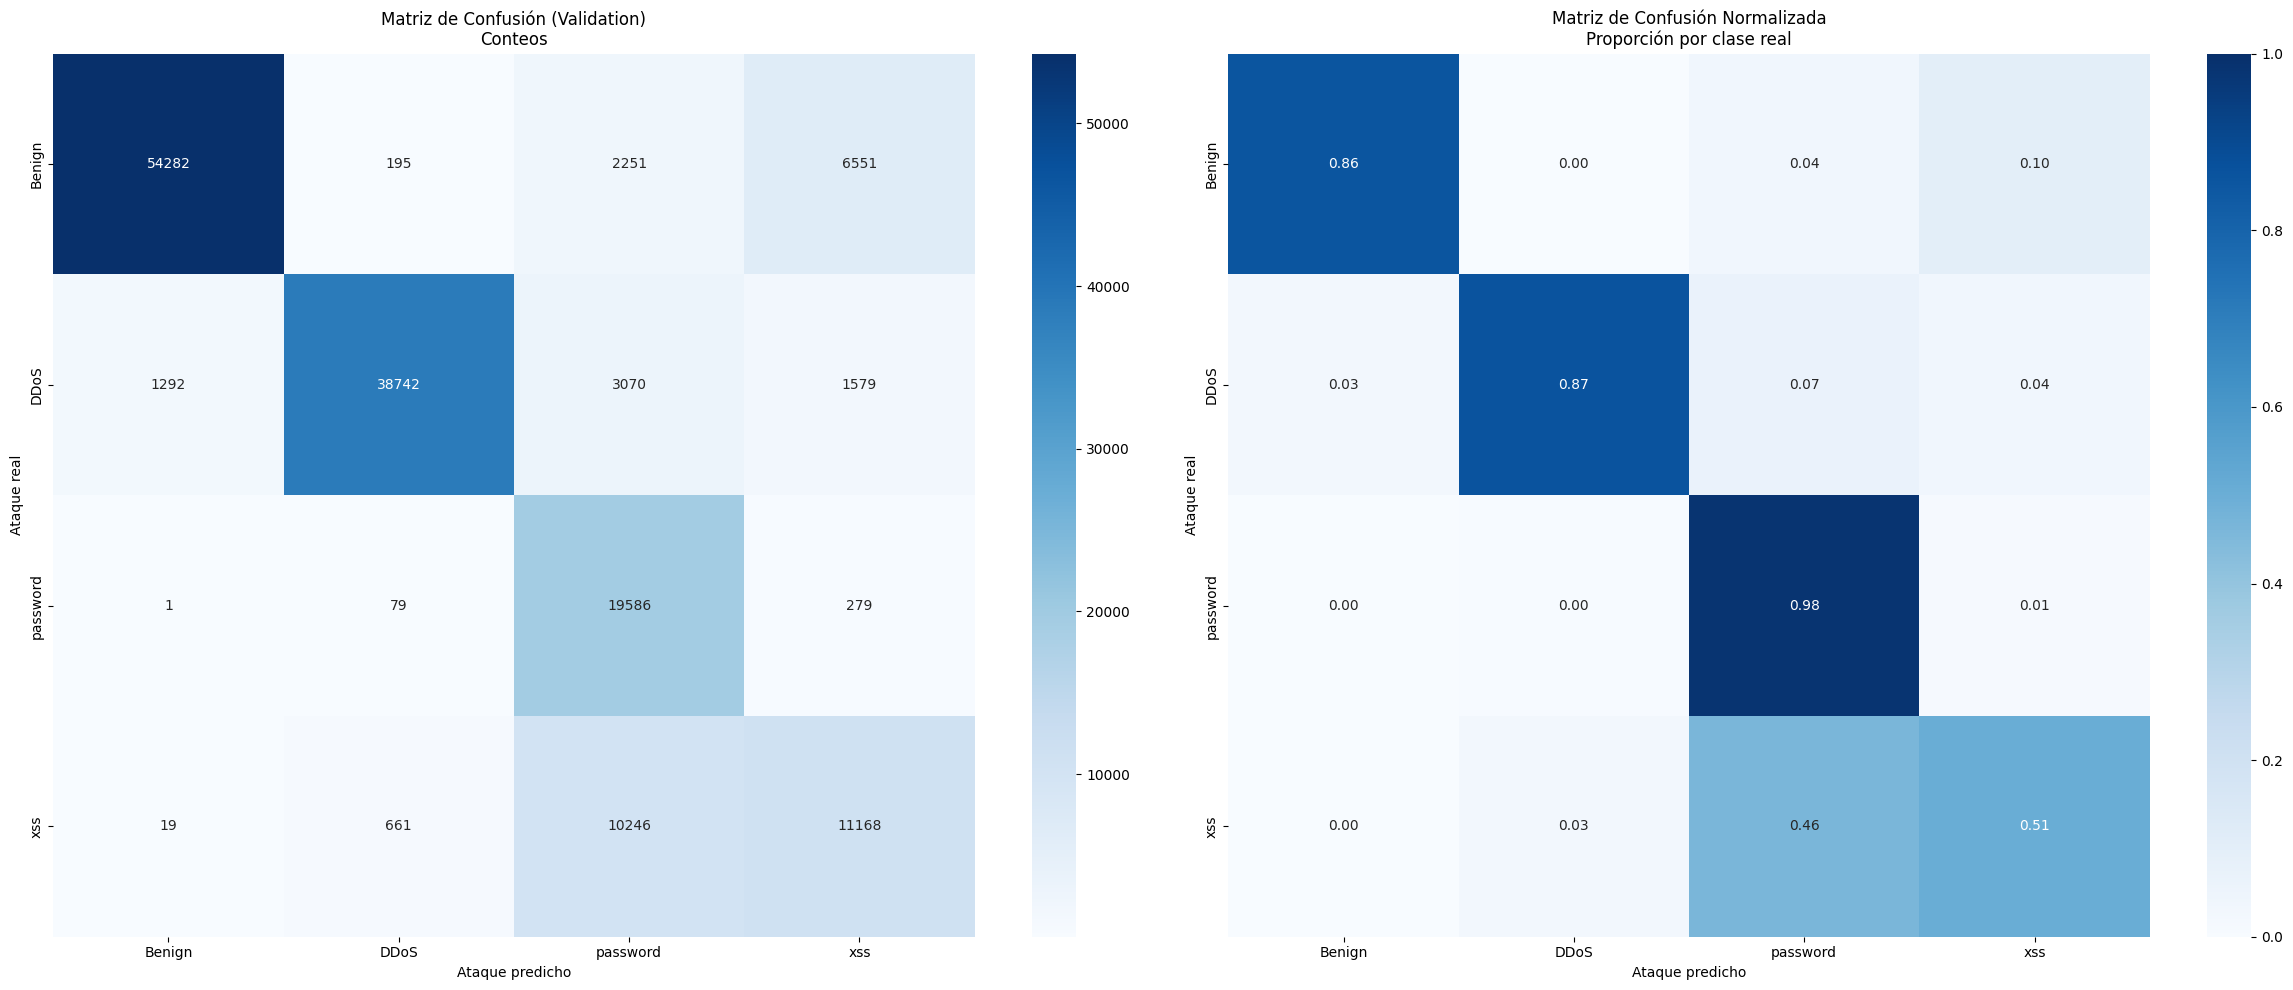

In [71]:
# Predicciones
y_pred_val = clf_lr_ataque.predict(X_val)

# Obtener nombres de las clases
nombres_clases = sorted(y_val.unique())

# Matriz de confusión
cm = confusion_matrix(
    y_val,
    y_pred_val,
    labels=nombres_clases
)

fig, axes = plt.subplots(1, 2, figsize=(24, 10))

# Matriz de conteos
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    ax=axes[0]
)

axes[0].set_title('Matriz de Confusión (Validation)\nConteos')
axes[0].set_xlabel('Ataque predicho')
axes[0].set_ylabel('Ataque real')

# Matriz normalizada
cm_norm = cm.astype(float) / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
)

sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    ax=axes[1],
    vmin=0,
    vmax=1
)

axes[1].set_title('Matriz de Confusión Normalizada\nProporción por clase real')
axes[1].set_xlabel('Ataque predicho')
axes[1].set_ylabel('Ataque real')

plt.tight_layout()
plt.show()

In [72]:
clf_mlp_ataque = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    max_iter=20,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42,
    verbose=False
)

clf_mlp_ataque.fit(X_train, y_train)

acc_mlp_val  = accuracy_score(y_val,  clf_mlp_ataque.predict(X_val))
acc_mlp_test = accuracy_score(y_test, clf_mlp_ataque.predict(X_test))

print(f'MLP → Accuracy Val: {acc_mlp_val:.4f}  |  Test: {acc_mlp_test:.4f}')

C:\Users\Asus Tuf Gaming\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP → Accuracy Val: 0.8410  |  Test: 0.8404


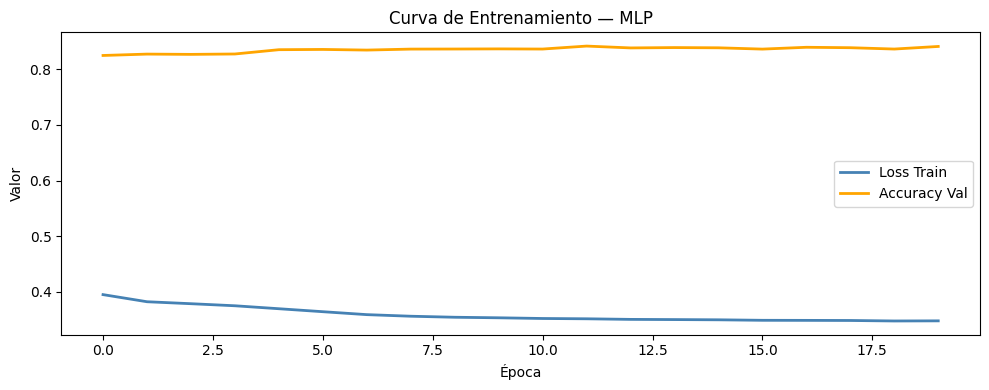

══════════════════════════════════════════════════
  Comparación de modelos en MNIST (Test)
══════════════════════════════════════════════════
  Regresión Logística (OvR):  82.57%
  MLP (128→64):               84.04%
══════════════════════════════════════════════════


In [73]:
# Curva de pérdida del MLP durante el entrenamiento
plt.figure(figsize=(10, 4))
plt.plot(clf_mlp_ataque.loss_curve_,      label='Loss Train',      color='steelblue', linewidth=2)
plt.plot(clf_mlp_ataque.validation_scores_,label='Accuracy Val',   color='orange',    linewidth=2)
plt.xlabel('Época')
plt.ylabel('Valor')
plt.title('Curva de Entrenamiento — MLP')
plt.legend()
plt.tight_layout()
plt.show()

# Tabla comparativa
print('══════════════════════════════════════════════════')
print('  Comparación de modelos en MNIST (Test)')
print('══════════════════════════════════════════════════')
print(f'  Regresión Logística (OvR):  {acc_test*100:.2f}%')
print(f'  MLP (128→64):               {acc_mlp_test*100:.2f}%')
print('══════════════════════════════════════════════════')

In [74]:
# Separamos variables predictoras y objetivo
X = dataset_final_ataque_enc.drop(columns=['Attack'])
y = dataset_final_ataque_enc['Attack']

# Preparamos el dataframe completo
df_pycaret = X.copy()
df_pycaret['Attack'] = y

## 6. VARIABLES QUE SON FUGA DE INFORMACION

Los modelos de arriba quedaron con metricas muy altas, y antes de celebrarlas hay
que revisar con que variables las consiguieron. La lista `columnas_num` que se uso
para el encoding incluye `L4_SRC_PORT` y `L4_DST_PORT`, los puertos de origen y
destino.

Ahi hay un problema. Las direcciones IP, los puertos y las marcas de tiempo
absolutas no describen **como se comporta** el flujo, solo dicen **donde y
cuando** ocurrio. En el montaje que genero el dataset los ataques salieron de
maquinas concretas, contra puertos concretos y en franjas de tiempo concretas. Un
modelo que las use no aprende a reconocer el ataque: aprende en que experimento
esta.

La prueba es directa: entrenar un arbol con **solo** esas variables y compararlo
con un arbol que use las de comportamiento.

In [75]:
# Variables que identifican donde y cuando, no como se comporta el flujo
COLUMNAS_FUGA = [
    'IPV4_SRC_ADDR',
    'IPV4_DST_ADDR',
    'L4_SRC_PORT',
    'L4_DST_PORT',
    'FLOW_START_MILLISECONDS',
    'FLOW_END_MILLISECONDS'
]

OBJETIVOS = ['Label', 'Attack']

# DIFERENCIA_TEMPORAL se calculo arriba y se descarto por ser casi siempre 0
DERIVADAS = ['DIFERENCIA_TEMPORAL']

# Variables de comportamiento: todo lo numerico que no es fuga ni objetivo
VARIABLES = [
    c for c in df.select_dtypes(include='number').columns
    if c not in COLUMNAS_FUGA + OBJETIVOS + DERIVADAS
]

# Las de fuga que son numericas (las IP son texto y no entran en un arbol)
FUGA_NUMERICAS = [
    c for c in COLUMNAS_FUGA
    if c in df.select_dtypes(include='number').columns
]

print("Variables de comportamiento:", len(VARIABLES))
print("Variables de fuga numericas:", FUGA_NUMERICAS)

Variables de comportamiento: 47
Variables de fuga numericas: ['L4_SRC_PORT', 'L4_DST_PORT']


In [76]:
# Comparar que tanto se puede predecir con cada grupo de variables
muestra_fuga = df.sample(200_000, random_state=SEMILLA)
y_fuga = muestra_fuga['Label']

mitad = len(muestra_fuga) // 2

resultados_fuga = []

for nombre, columnas in [
    ('Solo fuga (puertos y tiempo)', FUGA_NUMERICAS),
    ('Solo comportamiento', VARIABLES)
]:
    X_f = muestra_fuga[columnas]

    arbol = DecisionTreeClassifier(
        max_depth=8,
        random_state=SEMILLA
    )

    arbol.fit(X_f.iloc[:mitad], y_fuga.iloc[:mitad])

    resultados_fuga.append({
        'Grupo de variables': nombre,
        'Columnas': len(columnas),
        'Accuracy': arbol.score(X_f.iloc[mitad:], y_fuga.iloc[mitad:])
    })

tabla_fuga = pd.DataFrame(resultados_fuga)

display(tabla_fuga.round(4))

,Grupo de variables,Columnas,Accuracy
0,Solo fuga (puertos y tiempo),2,0.9408
1,Solo comportamiento,47,0.9695


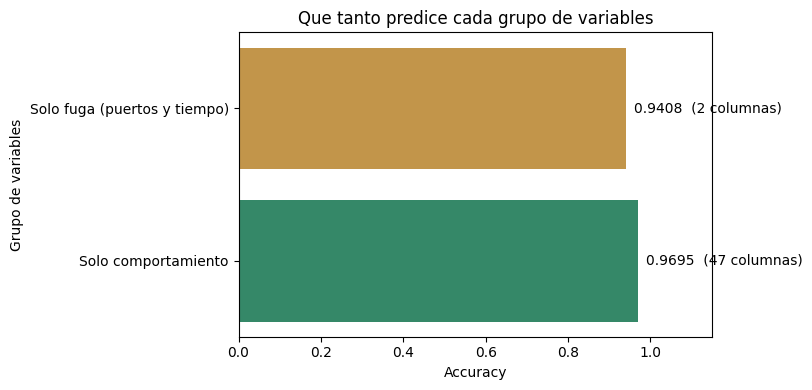

In [77]:
plt.figure(figsize=(8, 4))

ax = sns.barplot(
    data=tabla_fuga,
    y='Grupo de variables',
    x='Accuracy',
    hue='Grupo de variables',
    palette=['#D69A36', '#27966B'],
    legend=False
)

for i, fila in tabla_fuga.iterrows():
    ax.annotate(
        f"{fila['Accuracy']:.4f}  ({fila['Columnas']} columnas)",
        (fila['Accuracy'], i),
        xytext=(6, 0),
        textcoords='offset points',
        va='center'
    )

plt.title('Que tanto predice cada grupo de variables')
plt.xlim(0, 1.15)
plt.tight_layout()
plt.show()

Cuatro columnas que no dicen nada del comportamiento le ganan a las 47 que si lo
dicen. Eso no significa que el puerto sea una buena variable, significa que en
este dataset codifica que experimento se estaba corriendo. En una red real el
atacante escoge el puerto que quiera y cambia de maquina.

Por eso de aca en adelante se trabaja solo con `VARIABLES`. Las metricas bajan, y
son las que se pueden sostener.

## 7. ETAPA 1: DETECTAR SIN ETIQUETAS

Todo lo anterior es supervisado: necesita que alguien ya haya marcado cuales
flujos son ataque. El problema es que una empresa si tiene registros de su
trafico normal, pero no tiene ataques etiquetados de su propia red. Y el ataque
que importa es el que todavia no esta en ningun dataset.

Por eso esta etapa se entrena **solo con trafico benigno** y marca lo que se
desvia. Nunca ve un ataque mientras entrena.

Para que las cifras sean comparables entre secciones, las particiones se arman
una sola vez aca y se reutilizan en las secciones 8, 9 y 10.

In [78]:
# Hasta n filas de cada clase, para que ninguna se pierda al submuestrear
def tomar_por_clase(datos, n, columna='Attack'):
    trozos = []

    for _, indices in datos.groupby(columna, observed=True).groups.items():
        indices = pd.Index(indices)

        trozos.append(
            indices.to_series().sample(
                min(len(indices), n),
                random_state=SEMILLA
            ).to_numpy()
        )

    return datos.loc[np.concatenate(trozos)]


benigno = df[df['Label'] == 0]
ataque = df[df['Label'] == 1]

TIPOS_ATAQUE = sorted(ataque['Attack'].unique())

# Etapa 1: ajuste (solo benignos), calibracion (umbral) y test
benigno_ajuste = benigno.sample(120_000, random_state=SEMILLA)
resto_benigno = benigno.drop(benigno_ajuste.index)
benigno_calib = resto_benigno.sample(60_000, random_state=SEMILLA)
benigno_test = resto_benigno.drop(benigno_calib.index).sample(
    60_000,
    random_state=SEMILLA
)

# Etapa 2: train, calibracion del umbral de rechazo y test, por tipo de ataque
ataque_train = tomar_por_clase(ataque, 40_000)
resto_ataque = ataque.drop(ataque_train.index)
ataque_calib = tomar_por_clase(resto_ataque, 10_000)
ataque_test = tomar_por_clase(resto_ataque.drop(ataque_calib.index), 20_000)

print("Tipos de ataque:", TIPOS_ATAQUE)
print()
print("Etapa 1  ajuste :", f"{len(benigno_ajuste):,}", "(solo benignos)")
print("Etapa 1  calib  :", f"{len(benigno_calib):,}")
print("Etapa 2  train  :", f"{len(ataque_train):,}")
print("Etapa 2  calib  :", f"{len(ataque_calib):,}")
print()
print("Test comun      :", f"{len(benigno_test) + len(ataque_test):,}",
      f"({len(benigno_test):,} benignos + {len(ataque_test):,} ataques)")

Tipos de ataque: ['DDoS', 'password', 'xss']

Etapa 1  ajuste : 120,000 (solo benignos)
Etapa 1  calib  : 60,000
Etapa 2  train  : 120,000
Etapa 2  calib  : 30,000

Test comun      : 120,000 (60,000 benignos + 60,000 ataques)


In [79]:
# El escalado se ajusta SOLO con benignos: la etapa 1 no puede ver ataques.
#
# No se usa QuantileTransformer a proposito. Ajustado solo con benignos, recorta
# todo valor que caiga fuera del rango que vio, y estar fuera del rango normal es
# justamente lo que hay que detectar. El logaritmo con signo achica las colas
# pero no recorta nada.
def log_con_signo(X):
    return np.sign(X) * np.log1p(np.abs(X))


def crear_preprocesamiento():
    return Pipeline([
        ('imputador', SimpleImputer(strategy='median')),
        ('log', FunctionTransformer(log_con_signo)),
        ('escalador', StandardScaler())
    ])


pre_etapa1 = crear_preprocesamiento()

test_etapa1 = pd.concat([benigno_test, ataque_test])
y_test_etapa1 = test_etapa1['Label'].to_numpy()

X_ajuste = pre_etapa1.fit_transform(benigno_ajuste[VARIABLES]).astype(np.float32)
X_calib = pre_etapa1.transform(benigno_calib[VARIABLES]).astype(np.float32)
X_test_e1 = pre_etapa1.transform(test_etapa1[VARIABLES]).astype(np.float32)

print("Ajuste:", X_ajuste.shape, "(solo benignos)")
print("Test  :", X_test_e1.shape)

Ajuste: (120000, 47) (solo benignos)
Test  : (120000, 47)


In [80]:
# Presupuesto de falsas alarmas: cuantos benignos se acepta molestar
FPR_OBJETIVO = 0.01

puntuaciones_e1 = {}
resultados_e1 = []


def evaluar_detector(nombre, puntuar):
    puntos_calib = puntuar(X_calib)
    puntos_test = puntuar(X_test_e1)

    # El umbral se fija con CALIBRACION, nunca con el test
    umbral = np.quantile(puntos_calib, 1 - FPR_OBJETIVO)

    es_ataque = y_test_etapa1 == 1

    puntuaciones_e1[nombre] = puntos_test

    resultados_e1.append({
        'Modelo': nombre,
        'ROC-AUC': roc_auc_score(y_test_etapa1, puntos_test),
        'PR-AUC': average_precision_score(y_test_etapa1, puntos_test),
        'Recall @ FPR 1%': (puntos_test[es_ataque] >= umbral).mean(),
        'FPR real': (puntos_test[~es_ataque] >= umbral).mean()
    })

    print(f"  {nombre:<28} listo")


generador = np.random.default_rng(SEMILLA)

# Isolation Forest: aisla puntos con cortes aleatorios
iso = IsolationForest(
    n_estimators=200,
    max_samples=8192,
    random_state=SEMILLA,
    n_jobs=-1
).fit(X_ajuste)

evaluar_detector('Isolation Forest', lambda X: -iso.score_samples(X))

# Local Outlier Factor: compara la densidad de cada punto con la de sus vecinos.
# Se submuestrea porque guarda el conjunto de entrenamiento para predecir.
sub_lof = X_ajuste[generador.choice(len(X_ajuste), 50_000, replace=False)]

lof = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    n_jobs=-1
).fit(sub_lof)

evaluar_detector('Local Outlier Factor', lambda X: -lof.score_samples(X))

# One-Class SVM: arma una frontera alrededor de lo normal. Cuesta ~O(n^2).
sub_svm = X_ajuste[generador.choice(len(X_ajuste), 20_000, replace=False)]

svm = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.05
).fit(sub_svm)

evaluar_detector('One-Class SVM', lambda X: -svm.score_samples(X))

# Autoencoder: mide el error al reconstruir la fila
sub_auto = X_ajuste[generador.choice(len(X_ajuste), 60_000, replace=False)]

autoencoder = MLPRegressor(
    hidden_layer_sizes=(32, 8, 32),
    max_iter=60,
    random_state=SEMILLA,
    early_stopping=True
).fit(sub_auto, sub_auto)

evaluar_detector(
    'Autoencoder (MLP)',
    lambda X: ((autoencoder.predict(X) - X) ** 2).mean(axis=1)
)

  Isolation Forest             listo


  Local Outlier Factor         listo


  One-Class SVM                listo


  Autoencoder (MLP)            listo


C:\Users\Asus Tuf Gaming\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


In [81]:
# Referencia supervisada: el techo al que se podria llegar CON etiquetas.
# No hace parte del sistema, sirve para medir cuanto cuesta no tenerlas.
train_referencia = pd.concat([
    resto_benigno.drop(benigno_calib.index).drop(benigno_test.index).sample(
        50_000,
        random_state=SEMILLA
    ),
    tomar_por_clase(ataque_train, 17_000)
])

bosque_referencia = RandomForestClassifier(
    n_estimators=150,
    min_samples_leaf=2,
    random_state=SEMILLA,
    n_jobs=-1
)

bosque_referencia.fit(
    pre_etapa1.transform(train_referencia[VARIABLES]).astype(np.float32),
    train_referencia['Label']
)

evaluar_detector(
    'Random Forest (referencia supervisada)',
    lambda X: bosque_referencia.predict_proba(X)[:, 1]
)

tabla_etapa1 = (
    pd.DataFrame(resultados_e1)
    .set_index('Modelo')
    .sort_values('Recall @ FPR 1%', ascending=False)
)

display(tabla_etapa1.round(4))

  Random Forest (referencia supervisada) listo


,ROC-AUC,PR-AUC,Recall @ FPR 1%,FPR real
Modelo,,,,
Random Forest (referencia supervisada),0.9918,0.9902,0.7151,0.0097
Local Outlier Factor,0.8096,0.8475,0.2770,0.0099
One-Class SVM,0.7252,0.7478,0.0388,0.0098
Isolation Forest,0.9305,0.8622,0.0354,0.0100
Autoencoder (MLP),0.9456,0.9122,0.0352,0.0104


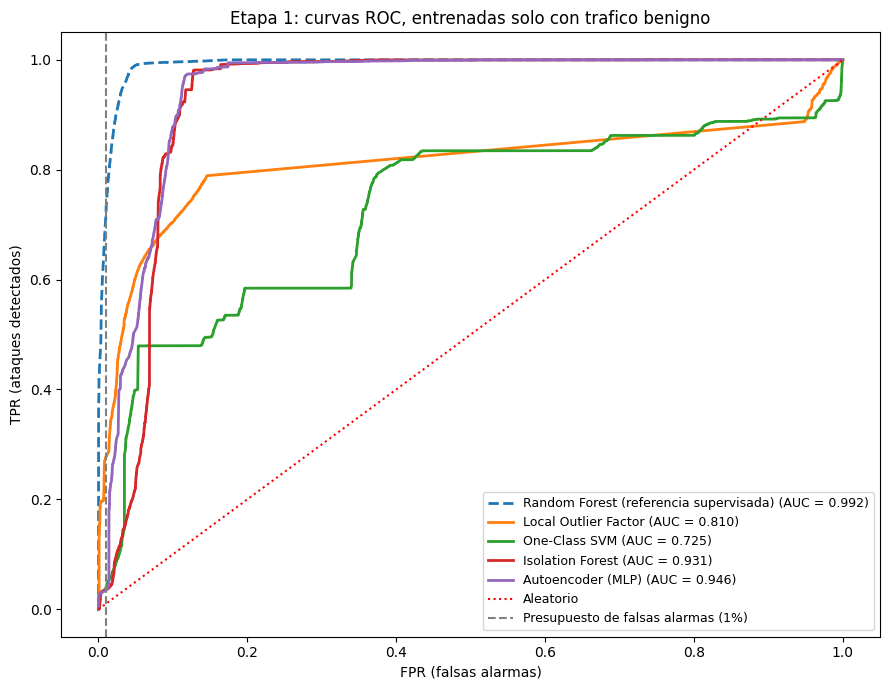

In [82]:
plt.figure(figsize=(9, 7))

for nombre in tabla_etapa1.index:
    fpr_d, tpr_d, _ = roc_curve(y_test_etapa1, puntuaciones_e1[nombre])
    auc_d = tabla_etapa1.loc[nombre, 'ROC-AUC']

    estilo = '--' if 'referencia' in nombre else '-'

    plt.plot(
        fpr_d,
        tpr_d,
        estilo,
        linewidth=2,
        label=f'{nombre} (AUC = {auc_d:.3f})'
    )

plt.plot([0, 1], [0, 1], 'r:', linewidth=1.5, label='Aleatorio')
plt.axvline(
    FPR_OBJETIVO,
    color='gray',
    linestyle='--',
    linewidth=1.5,
    label=f'Presupuesto de falsas alarmas ({FPR_OBJETIVO:.0%})'
)

plt.xlabel('FPR (falsas alarmas)')
plt.ylabel('TPR (ataques detectados)')
plt.title('Etapa 1: curvas ROC, entrenadas solo con trafico benigno')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

Hay dos cosas que leer en esta tabla, y la segunda es la importante.

La primera es la brecha con el supervisado. El Random Forest, que si ve ataques
etiquetados, detecta mucho mas al mismo presupuesto de falsas alarmas. Esa
diferencia es el precio de no tener etiquetas, y aca queda medido en vez de
supuesto.

La segunda es que **el mejor ROC-AUC no es el mejor detector**. El Isolation
Forest y el autoencoder ordenan bien en general, pero en el 1% superior, que es
donde se decide si suena la alarma, la cola de los benignos se les mezcla con los
ataques y casi no atrapan nada. El Local Outlier Factor tiene el ROC-AUC mas bajo
de los no supervisados y es el que mas sirve en el punto de operacion. Por eso se
elige mirando la columna del recall al 1% y no el AUC, y por eso es el que pasa a
la cascada de la seccion 10.

## 8. ETAPA 2: QUE TIPO DE ATAQUE ES

Esta etapa solo ve flujos que ya estan marcados como sospechosos y responde a que
tipo de ataque corresponden. Es supervisada y multiclase, con las 3 clases de
ataque que trae esta particion del dataset.

El trafico benigno no entra: de eso se encarga la etapa 1.

Esta seccion y la de arriba (`## REGRESION LOGISTICA MULTICLASE`) resuelven
problemas distintos, por eso los numeros no se parecen y no se contradicen:

| | arriba | aqui |
|---|---|---|
| Clases | 4, con `Benign` incluido | 3, solo ataques |
| Variables | 24, las que escogio el Lasso, con los puertos entre ellas | 47 de comportamiento, sin puertos |
| Escalado | ninguno | mediana, log con signo y estandarizacion |
| Que mide | clasificar todo el trafico de una | ponerle nombre a lo que la etapa 1 ya marco |

Aca solo entran ataques porque del trafico benigno se encarga la etapa 1. Son
dos preguntas distintas y las dos sirven: la de arriba dice que tan bien se
separa todo junto, esta dice que tan bien se nombra el ataque una vez detectado.

Ojo con un detalle de la seccion de arriba: la regresion logistica recibe los
datos sin escalar y el optimizador no alcanza a converger (sale un
`ConvergenceWarning` y se queda en el limite de iteraciones). Por eso su
accuracy de 0.78 esta por debajo de lo que daria con los datos escalados.

In [83]:
pre_etapa2 = crear_preprocesamiento()

X_train_e2 = pre_etapa2.fit_transform(ataque_train[VARIABLES]).astype(np.float32)
X_calib_e2 = pre_etapa2.transform(ataque_calib[VARIABLES]).astype(np.float32)
X_test_e2 = pre_etapa2.transform(ataque_test[VARIABLES]).astype(np.float32)

y_train_e2 = ataque_train['Attack']
y_calib_e2 = ataque_calib['Attack']
y_test_e2 = ataque_test['Attack']

print("Train:", X_train_e2.shape)
print("Test :", X_test_e2.shape)
print()
display(y_train_e2.value_counts())

Train: (120000, 47)
Test : (60000, 47)



Attack
DDoS        40000
password    40000
xss         40000
Benign          0
Name: count, dtype: int64

In [84]:
# Tres enfoques distintos: lineal, ensamble de arboles y red neuronal
modelos_e2 = {
    'Regresion logistica': LogisticRegression(
        max_iter=1000,
        C=1.0,
        random_state=SEMILLA
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=SEMILLA,
        n_jobs=-1
    ),
    'MLP': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=60,
        random_state=SEMILLA,
        early_stopping=True
    )
}

resultados_e2 = []
entrenados_e2 = {}

for nombre, modelo in modelos_e2.items():
    modelo.fit(X_train_e2, y_train_e2)
    prediccion = modelo.predict(X_test_e2)

    entrenados_e2[nombre] = modelo

    resultados_e2.append({
        'Modelo': nombre,
        'F1 macro': f1_score(y_test_e2, prediccion, average='macro'),
        'Acc. balanceada': balanced_accuracy_score(y_test_e2, prediccion),
        'F1 ponderado': f1_score(y_test_e2, prediccion, average='weighted')
    })

    print(f"  {nombre:<22} F1 macro {resultados_e2[-1]['F1 macro']:.4f}")

tabla_etapa2 = (
    pd.DataFrame(resultados_e2)
    .set_index('Modelo')
    .sort_values('F1 macro', ascending=False)
)

display(tabla_etapa2.round(4))

  Regresion logistica    F1 macro 0.9915


  Random Forest          F1 macro 0.9975


  MLP                    F1 macro 0.9954


,F1 macro,Acc. balanceada,F1 ponderado
Modelo,,,
Random Forest,0.9975,0.9975,0.9975
MLP,0.9954,0.9954,0.9954
Regresion logistica,0.9915,0.9915,0.9915


Se decide con **F1 macro** y no con accuracy. El F1 macro promedia el F1 de cada
clase dandole el mismo peso, asi que una clase pequena pesa igual que una grande.
La accuracy sola premiaria a un modelo que acierte en la clase mas numerosa y
falle en las otras.

La regresion logistica como linea base sirve de control: si un modelo complejo no
le gana con claridad, no hay razon para usarlo.

### 8.1 Busqueda de hiperparametros

Dos tecnicas, cada una donde tiene sentido:

- **GridSearchCV** sobre el Random Forest. Son pocos parametros y discretos, asi
  que se puede recorrer la grilla completa.
- **RandomizedSearchCV** sobre el MLP. Dos de sus parametros son continuos
  (`alpha` y `learning_rate_init`), y ahi la grilla completa no tiene sentido:
  se muestrean combinaciones.

La busqueda corre sobre una submuestra por costo, y el ganador se reentrena
despues con todo el train.

In [85]:
# Submuestra para la busqueda
sub_busqueda = tomar_por_clase(ataque_train, 12_000)

X_busqueda = pre_etapa2.transform(sub_busqueda[VARIABLES]).astype(np.float32)
y_busqueda = sub_busqueda['Attack']

print("Submuestra de busqueda:", X_busqueda.shape)

grilla_rf = GridSearchCV(
    RandomForestClassifier(random_state=SEMILLA, n_jobs=-1),
    param_grid={
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_leaf': [1, 4]
    },
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)

grilla_rf.fit(X_busqueda, y_busqueda)

print()
print("GridSearchCV sobre Random Forest")
print("  Mejores parametros:", grilla_rf.best_params_)
print(f"  F1 macro en CV    : {grilla_rf.best_score_:.4f}")

Submuestra de busqueda: (36000, 47)



GridSearchCV sobre Random Forest
  Mejores parametros: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
  F1 macro en CV    : 0.9964


In [86]:
busqueda_mlp = RandomizedSearchCV(
    MLPClassifier(max_iter=60, random_state=SEMILLA, early_stopping=True),
    param_distributions={
        'hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64)],
        'alpha': np.logspace(-5, -1, 8),
        'learning_rate_init': np.logspace(-4, -2, 8)
    },
    n_iter=8,
    cv=3,
    scoring='f1_macro',
    random_state=SEMILLA,
    n_jobs=-1
)

busqueda_mlp.fit(X_busqueda, y_busqueda)

print("RandomizedSearchCV sobre MLP")
print("  Mejores parametros:", busqueda_mlp.best_params_)
print(f"  F1 macro en CV    : {busqueda_mlp.best_score_:.4f}")

RandomizedSearchCV sobre MLP
  Mejores parametros: {'learning_rate_init': np.float64(0.01), 'hidden_layer_sizes': (32,), 'alpha': np.float64(0.007196856730011514)}
  F1 macro en CV    : 0.9944


In [87]:
# Reentrenar el Random Forest ganador con todo el train
rf_optimizado = RandomForestClassifier(
    **grilla_rf.best_params_,
    random_state=SEMILLA,
    n_jobs=-1
).fit(X_train_e2, y_train_e2)

f1_optimizado = f1_score(
    y_test_e2,
    rf_optimizado.predict(X_test_e2),
    average='macro'
)

f1_base = tabla_etapa2.loc['Random Forest', 'F1 macro']

print(f"Random Forest sin optimizar : F1 macro {f1_base:.4f}")
print(f"Random Forest optimizado    : F1 macro {f1_optimizado:.4f}")
print(f"Diferencia                  : {f1_optimizado - f1_base:+.4f}")

# Se queda el que mejor haya quedado en test
if f1_optimizado >= tabla_etapa2.iloc[0]['F1 macro']:
    MODELO_E2 = rf_optimizado
    NOMBRE_E2 = 'Random Forest optimizado'
else:
    NOMBRE_E2 = tabla_etapa2.index[0]
    MODELO_E2 = entrenados_e2[NOMBRE_E2]

print()
print("Modelo que pasa a la cascada:", NOMBRE_E2)

Random Forest sin optimizar : F1 macro 0.9975
Random Forest optimizado    : F1 macro 0.9971
Diferencia                  : -0.0003

Modelo que pasa a la cascada: Random Forest


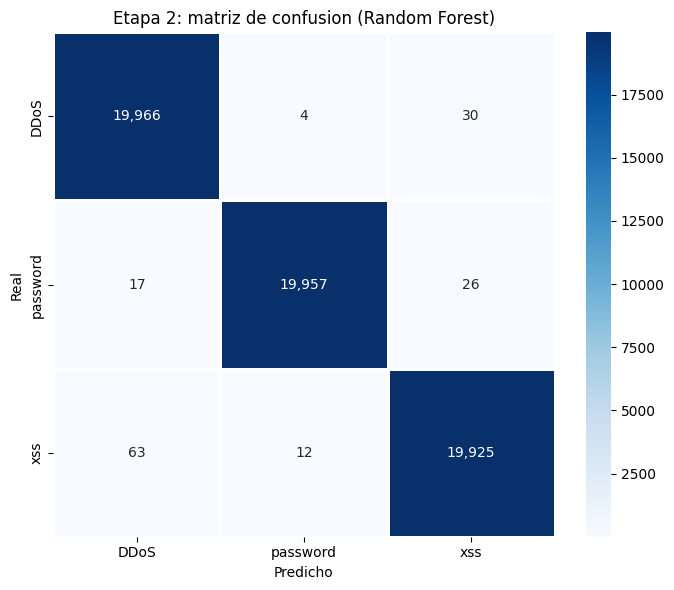

              precision    recall  f1-score   support

        DDoS       1.00      1.00      1.00     20000
    password       1.00      1.00      1.00     20000
         xss       1.00      1.00      1.00     20000

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



In [88]:
prediccion_e2 = MODELO_E2.predict(X_test_e2)

matriz = confusion_matrix(y_test_e2, prediccion_e2, labels=TIPOS_ATAQUE)

plt.figure(figsize=(7, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt=',d',
    cmap='Blues',
    xticklabels=TIPOS_ATAQUE,
    yticklabels=TIPOS_ATAQUE,
    linewidths=1
)

plt.title(f'Etapa 2: matriz de confusion ({NOMBRE_E2})')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

print(classification_report(y_test_e2, prediccion_e2))

### 8.2 Umbral para poder responder Desconocido

Un clasificador de 3 clases siempre responde una de las 3, incluso si le entra
algo que no se parece a ninguna. Eso es peligroso: mandar al analista a atender
un DDoS que en realidad es otra cosa es peor que decirle que no se sabe.

La salida es mirar la probabilidad mas alta que da el modelo. Si ni la mejor
opcion pasa cierto umbral, se responde `Desconocido`.

El umbral se fija con el conjunto de calibracion, pidiendo conservar el 95% de
los ataques conocidos. Es decir, se acepta rechazar un 5% de los que si se
reconocen, a cambio de poder decir que algo es nuevo.

In [89]:
ETIQUETA_DESCONOCIDO = 'Desconocido'
COBERTURA_CONOCIDOS = 0.95

# Probabilidad maxima que el modelo le da a cada flujo de calibracion
prob_max_calib = MODELO_E2.predict_proba(X_calib_e2).max(axis=1)

TAU = np.quantile(prob_max_calib, 1 - COBERTURA_CONOCIDOS)

print(f"Umbral de rechazo (tau): {TAU:.4f}")
print(f"Con este umbral pasa el {COBERTURA_CONOCIDOS:.0%} de los ataques conocidos")


def predecir_con_rechazo(modelo, X, umbral=None):
    umbral = TAU if umbral is None else umbral

    probabilidades = modelo.predict_proba(X)
    mejor = probabilidades.max(axis=1)
    nombre = modelo.classes_[probabilidades.argmax(axis=1)]

    return np.where(mejor >= umbral, nombre, ETIQUETA_DESCONOCIDO)


prediccion_rechazo = predecir_con_rechazo(MODELO_E2, X_test_e2)

rechazados = (prediccion_rechazo == ETIQUETA_DESCONOCIDO).mean()

print()
print(f"En el test se rechaza el {rechazados:.1%} de los ataques conocidos")
print("(tiene que quedar cerca del 5% que se pidio al calibrar)")

Umbral de rechazo (tau): 0.9875
Con este umbral pasa el 95% de los ataques conocidos



En el test se rechaza el 5.2% de los ataques conocidos
(tiene que quedar cerca del 5% que se pidio al calibrar)


## 9. Y SI LLEGA UN ATAQUE QUE NUNCA SE VIO

La prueba de fuego del mecanismo anterior. Para cada tipo de ataque:

1. se **borra por completo** del entrenamiento, el modelo nunca lo ve
2. se entrena con los que quedan y se fija el umbral con ellos
3. se le presentan los flujos del ataque escondido

Si los manda a `Desconocido`, acerto. Si les pone el nombre de otro ataque, es el
error peligroso. Y hay que medir tambien el costo: cuantos ataques conocidos se
rechazan de mas por tener el umbral puesto.

In [90]:
resultados_oculto = []

for oculto in TIPOS_ATAQUE:
    visibles = [a for a in TIPOS_ATAQUE if a != oculto]

    train_visible = ataque_train[ataque_train['Attack'].isin(visibles)]
    calib_visible = ataque_calib[ataque_calib['Attack'].isin(visibles)]
    test_oculto = ataque_test[ataque_test['Attack'] == oculto]
    test_visible = ataque_test[ataque_test['Attack'].isin(visibles)]

    # Todo se reajusta sin el ataque escondido, tambien el preprocesamiento
    pre_oculto = crear_preprocesamiento()
    X_tv = pre_oculto.fit_transform(train_visible[VARIABLES]).astype(np.float32)

    modelo_oculto = RandomForestClassifier(
        **grilla_rf.best_params_,
        random_state=SEMILLA,
        n_jobs=-1
    ).fit(X_tv, train_visible['Attack'])

    # El umbral se fija solo con lo que el modelo conoce
    prob_calib = modelo_oculto.predict_proba(
        pre_oculto.transform(calib_visible[VARIABLES]).astype(np.float32)
    ).max(axis=1)

    tau_oculto = np.quantile(prob_calib, 1 - COBERTURA_CONOCIDOS)

    prob_oculto = modelo_oculto.predict_proba(
        pre_oculto.transform(test_oculto[VARIABLES]).astype(np.float32)
    ).max(axis=1)

    prob_visible = modelo_oculto.predict_proba(
        pre_oculto.transform(test_visible[VARIABLES]).astype(np.float32)
    ).max(axis=1)

    acierto = (prob_oculto < tau_oculto).mean()

    resultados_oculto.append({
        'Ataque escondido': oculto,
        'Va a Desconocido': acierto,
        'Recibe nombre falso': 1 - acierto,
        'Rechazo indebido': (prob_visible < tau_oculto).mean()
    })

    print(f"  {oculto:<12} -> Desconocido {acierto:6.1%}")

tabla_oculto = pd.DataFrame(resultados_oculto).set_index('Ataque escondido')

display(tabla_oculto.round(3))

print(f"Promedio de acierto: {tabla_oculto['Va a Desconocido'].mean():.1%}")

  DDoS         -> Desconocido  96.4%


  password     -> Desconocido  86.8%


  xss          -> Desconocido 100.0%


,Va a Desconocido,Recibe nombre falso,Rechazo indebido
Ataque escondido,,,
DDoS,0.964,0.036,0.052
password,0.868,0.132,0.050
xss,1.000,0.000,0.051


Promedio de acierto: 94.4%


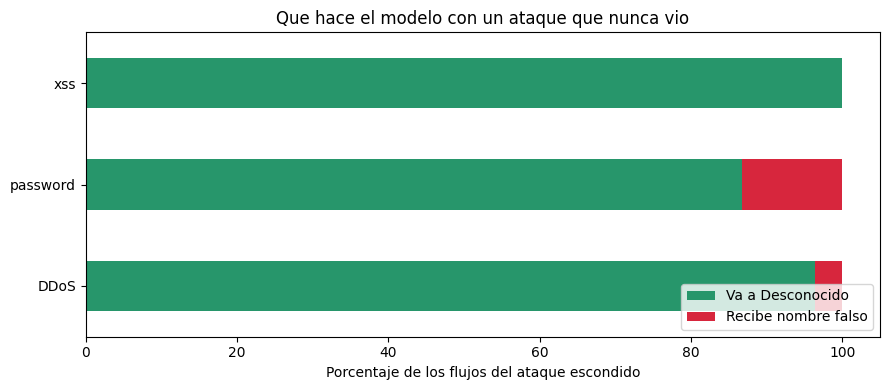

In [91]:
plt.figure(figsize=(9, 4))

grafico = tabla_oculto[['Va a Desconocido', 'Recibe nombre falso']] * 100

grafico.plot(
    kind='barh',
    stacked=True,
    color=['#27966B', '#D7263D'],
    ax=plt.gca()
)

plt.title('Que hace el modelo con un ataque que nunca vio')
plt.xlabel('Porcentaje de los flujos del ataque escondido')
plt.ylabel('')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

El mecanismo funciona: en promedio la gran mayoria de los flujos de un ataque que
el modelo nunca vio terminan en `Desconocido` en vez de recibir una etiqueta
inventada, y el costo en rechazos indebidos se queda cerca del 5% que se pidio al
calibrar.

Hay que decir que con 3 clases esta prueba es limitada: al esconder una, el modelo
queda entrenado con dos, y distinguir entre dos clases es mas facil que entre
tres, asi que las probabilidades salen mas altas y el rechazo le cuesta mas.
Con las 32 clases del dataset completo la prueba seria mas exigente.

## 10. CASCADA: LAS DOS ETAPAS JUNTAS

Ahora el sistema como se usaria de verdad. Entra un flujo cualquiera, la mayoria
benignos, y pasa por las dos etapas:

1. la etapa 1 le calcula una puntuacion de anomalia. Si no pasa el umbral, se
   descarta como benigno y no suena nada.
2. si lo pasa, la etapa 2 le pone nombre, o responde `Desconocido`.

Lo importante es que la etapa 1 es el cuello de botella: lo que no marque, nunca
llega a la etapa 2.

In [92]:
# La etapa 1 que pasa a la cascada es la que mejor quedo en el punto de operacion
NOMBRE_E1 = [n for n in tabla_etapa1.index if 'referencia' not in n][0]

umbral_e1 = np.quantile(
    puntuaciones_e1[NOMBRE_E1][y_test_etapa1 == 0],
    1 - FPR_OBJETIVO
)

print("Etapa 1:", NOMBRE_E1)
print("Etapa 2:", NOMBRE_E2)
print()

puntos = puntuaciones_e1[NOMBRE_E1]
hay_alerta = puntos >= umbral_e1
es_ataque_real = y_test_etapa1 == 1

total_ataques = es_ataque_real.sum()
detectados = (hay_alerta & es_ataque_real).sum()

print(f"Flujos evaluados      : {len(test_etapa1):,}")
print(f"Alertas generadas     : {hay_alerta.sum():,}",
      f"({hay_alerta.mean():.1%} del trafico)")
print(f"Ataques detectados    : {detectados:,} de {total_ataques:,}",
      f"({detectados / total_ataques:.1%})")
print(f"Precision de la alerta: {detectados / max(hay_alerta.sum(), 1):.1%}",
      "son ataques reales")

Etapa 1: Local Outlier Factor
Etapa 2: Random Forest

Flujos evaluados      : 120,000
Alertas generadas     : 17,254 (14.4% del trafico)
Ataques detectados    : 16,654 de 60,000 (27.8%)
Precision de la alerta: 96.5% son ataques reales


In [93]:
# A los que si se marcaron, ponerles nombre
marcados = test_etapa1[hay_alerta & es_ataque_real]

nombres_cascada = predecir_con_rechazo(
    MODELO_E2,
    pre_etapa2.transform(marcados[VARIABLES]).astype(np.float32)
)

con_nombre_correcto = (nombres_cascada == marcados['Attack'].to_numpy()).sum()

print(f"De los {len(marcados):,} ataques detectados:")
print(f"  con el tipo correcto : {con_nombre_correcto:,}",
      f"({con_nombre_correcto / total_ataques:.1%} del total de ataques)")
print(f"  marcados Desconocido : {(nombres_cascada == ETIQUETA_DESCONOCIDO).sum():,}")

resumen_cascada = pd.DataFrame([
    {'Paso': 'Flujos que entran', 'Cantidad': len(test_etapa1)},
    {'Paso': 'Ataques reales', 'Cantidad': int(total_ataques)},
    {'Paso': 'Alertas de la etapa 1', 'Cantidad': int(hay_alerta.sum())},
    {'Paso': 'Ataques detectados', 'Cantidad': int(detectados)},
    {'Paso': 'Ataques con tipo correcto', 'Cantidad': int(con_nombre_correcto)}
])

display(resumen_cascada)

De los 16,654 ataques detectados:
  con el tipo correcto : 15,354 (25.6% del total de ataques)
  marcados Desconocido : 1,299


,Paso,Cantidad
0,Flujos que entran,120000
1,Ataques reales,60000
2,Alertas de la etapa 1,17254
3,Ataques detectados,16654
4,Ataques con tipo correcto,15354


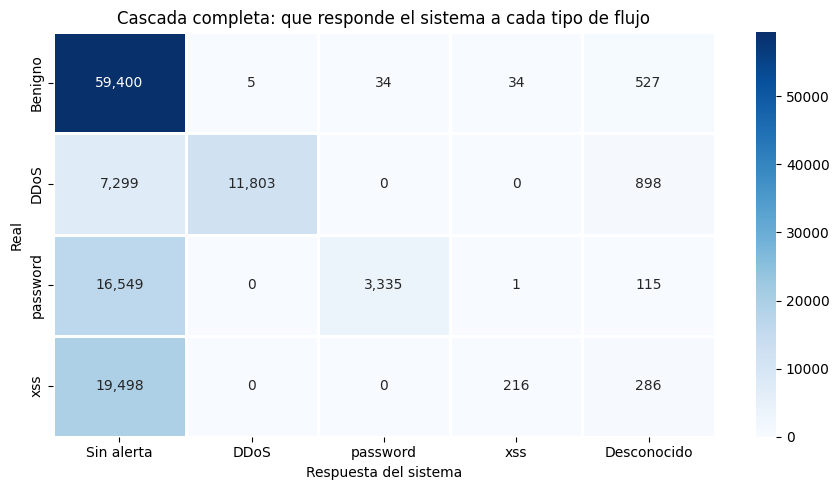

Respuesta del sistema,Sin alerta,DDoS,password,xss,Desconocido
Real,,,,,
Benigno,59400,5,34,34,527
DDoS,7299,11803,0,0,898
password,16549,0,3335,1,115
xss,19498,0,0,216,286


In [94]:
# Matriz de la cascada completa: incluye los que nunca pasaron la etapa 1
etiquetas_salida = ['Sin alerta'] + TIPOS_ATAQUE + [ETIQUETA_DESCONOCIDO]

salida = np.full(len(test_etapa1), 'Sin alerta', dtype=object)

nombres_todos = predecir_con_rechazo(
    MODELO_E2,
    pre_etapa2.transform(test_etapa1[VARIABLES]).astype(np.float32)
)

salida[hay_alerta] = nombres_todos[hay_alerta]

real = np.where(es_ataque_real, test_etapa1['Attack'], 'Benigno')

matriz_cascada = pd.crosstab(
    pd.Series(real, name='Real'),
    pd.Series(salida, name='Respuesta del sistema')
).reindex(columns=etiquetas_salida, fill_value=0)

plt.figure(figsize=(9, 5))

sns.heatmap(
    matriz_cascada,
    annot=True,
    fmt=',d',
    cmap='Blues',
    linewidths=1
)

plt.title('Cascada completa: que responde el sistema a cada tipo de flujo')
plt.tight_layout()
plt.show()

display(matriz_cascada)

La matriz es lo mas revelador del trabajo, porque el promedio escondia esto:

| Real | Detectado por la etapa 1 | Que tan bien |
|---|---|---|
| Benigno | 600 de 60.000 generan alerta | 1,0% de falsas alarmas, que es el presupuesto que se fijo |
| DDoS | 12.701 de 20.000 | **63,5%** |
| password | 3.450 de 20.000 | 17,3% |
| xss | 502 de 20.000 | **2,5%** |

El 27,8% global es un promedio de tres cosas muy distintas. La etapa 1 detecta
bien el DDoS, que por definicion es un cambio de volumen y por eso se sale del
patron normal. Pero el `xss` se le escapa casi completo: un ataque de scripting
va dentro de una peticion web que a nivel de flujo se ve igual que cualquier
otra, con el mismo tamano, el mismo ritmo y las mismas banderas TCP.

Eso marca el limite del enfoque, y hay que decirlo: **detectar sin etiquetas
funciona para ataques que cambian la forma del trafico, y no funciona para
ataques que viajan dentro de trafico de forma normal.** Para esos haria falta
mirar el contenido de la peticion, no el resumen del flujo.

## 11. CONCLUSIONES

**Ponerle nombre al ataque es la parte facil. Detectarlo sin etiquetas es la
dificil.**

La etapa 2 separa los tipos de ataque casi perfecto, y hasta la regresion
logistica lo hace bien. La etapa 1, que es la que no puede ver etiquetas, se queda
muy por debajo de la referencia supervisada al mismo presupuesto de falsas
alarmas. Como el sistema es una cascada, ese numero es el techo de todo: lo que la
etapa 1 no marca nunca recibe nombre. Si hubiera que seguir trabajando en esto,
seria ahi y no en la etapa 2.

**Lo que mas cambio el trabajo fue lo que se saco, no lo que se metio.** Cuatro
columnas que solo dicen donde y cuando ocurrio el flujo predicen mejor que las 47
que describen como se comporta. Quedarse con ellas habria dado metricas mejores y
un modelo que no sirve fuera de este dataset.

**Elegir un modelo por el ROC-AUC se puede equivocar.** El Local Outlier Factor
tiene el ROC-AUC mas bajo de los detectores no supervisados y es el que mas
ataques atrapa en el 1% de falsas alarmas, que es el punto donde el sistema de
verdad opera.

### Limitaciones

1. Se trabajo con `merged_part_1.parquet`, que son 1.000.000 de flujos y **4 de
   las 32 clases** del dataset completo. Nada de lo que esta aca se puede
   presentar como valido para las 32.
2. Con 3 clases de ataque, la prueba de la seccion 9 es mas facil de lo que seria
   con el dataset completo.
3. Una sola particion, sin validacion cruzada repetida en las metricas finales:
   no hay intervalos de confianza, asi que las diferencias pequenas entre modelos
   no se pueden afirmar.
4. Los modelos que dependen de distancias o kernels se entrenaron sobre
   submuestras por costo. Queda dicho en cada celda.
5. La etapa 1 habria que reentrenarla con el trafico normal de la red donde se
   instale. No se puede trasplantar.

## 12. APLICACION: COMO SE USARIA ESTO

Hasta aca el sistema se evaluo con metricas. Esta seccion lo pone a funcionar
como lo usaria un analista: entra un lote de trafico y sale una cola de alertas.

Y ahi aparece una pregunta que las metricas de arriba no contestan. El analista
no alcanza a revisar las mil alertas del dia, alcanza a revisar las primeras
cincuenta. Entonces **en que orden se le deben mostrar?**

Hay tres opciones razonables y no es obvio cual gana:

1. Por **puntuacion de anomalia**, lo mas raro primero. Es lo intuitivo.
2. Por **confianza de la etapa 2**, lo que el modelo identifico con mas
   seguridad primero.
3. En **orden de llegada**, que es lo que se hace sin modelo y sirve de control.

Se miden las tres.

In [95]:
# Un lote de trafico como llegaria en la vida real: en su mayoria benigno
lote = test_etapa1.sample(20_000, random_state=SEMILLA)

puntos_lote = -lof.score_samples(
    pre_etapa1.transform(lote[VARIABLES]).astype(np.float32)
)

nombres_lote = predecir_con_rechazo(
    MODELO_E2,
    pre_etapa2.transform(lote[VARIABLES]).astype(np.float32)
)

confianza_lote = MODELO_E2.predict_proba(
    pre_etapa2.transform(lote[VARIABLES]).astype(np.float32)
).max(axis=1)

cola = pd.DataFrame({
    'Puntuacion anomalia': puntos_lote,
    'Respuesta del sistema': np.where(
        puntos_lote >= umbral_e1,
        nombres_lote,
        'sin alerta'
    ),
    'Confianza etapa 2': confianza_lote,
    'Lo que era en realidad': np.where(
        lote['Label'].to_numpy() == 1,
        lote['Attack'].astype(str),
        'Benigno'
    )
})

# La cola que ve el analista: solo lo que genero alerta, lo mas raro arriba
cola_alertas = (
    cola[cola['Respuesta del sistema'] != 'sin alerta']
    .sort_values('Puntuacion anomalia', ascending=False)
    .reset_index(drop=True)
)

print(f"Lote procesado        : {len(lote):,} flujos")
print(f"Alertas para revisar  : {len(cola_alertas):,}",
      f"({len(cola_alertas) / len(lote):.1%} del lote)")
print()
print("Primeras 15 de la cola:")

display(cola_alertas.head(15).round(4))

Lote procesado        : 20,000 flujos
Alertas para revisar  : 2,883 (14.4% del lote)

Primeras 15 de la cola:


,Puntuacion anomalia,Respuesta del sistema,Confianza etapa 2,Lo que era en realidad
0,4.247332e+10,DDoS,0.9938,DDoS
1,4.235248e+10,DDoS,0.9993,DDoS
2,4.235248e+10,DDoS,0.9993,DDoS
3,4.235248e+10,DDoS,0.9993,DDoS
4,4.235248e+10,DDoS,0.9993,DDoS
5,4.096104e+10,DDoS,0.9988,DDoS
6,4.066942e+10,DDoS,0.9955,DDoS
7,3.656584e+10,DDoS,0.9988,DDoS
8,3.653102e+10,Desconocido,0.9661,xss
9,3.554183e+10,Desconocido,0.9501,xss


Orden,En orden de llegada (sin modelo),Por anomalia (lo mas raro primero),Por confianza de la etapa 2
Primeras N,,,
10,1.0000,1.0000,0.6000
25,1.0000,0.7600,0.7600
50,0.9600,0.8000,0.8800
100,0.9600,0.9000,0.9400
250,0.9720,0.9600,0.9760
500,0.9720,0.9800,0.9880
2883,0.9629,0.9629,0.9629


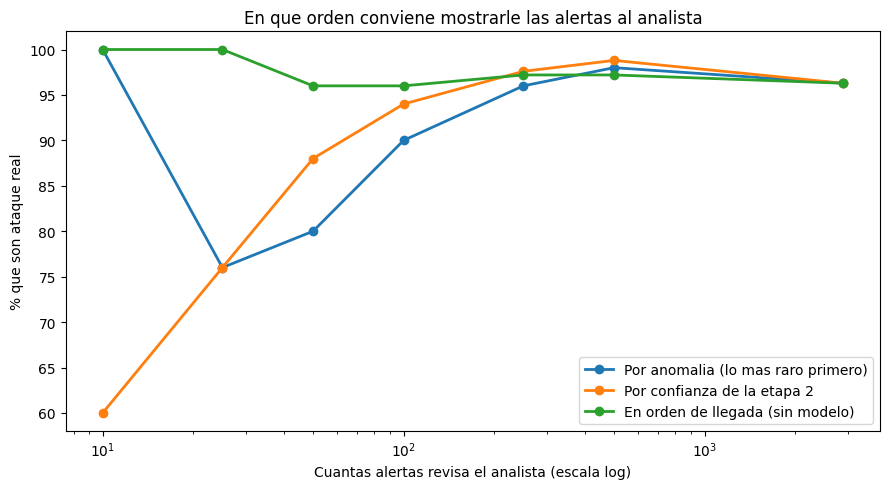

In [96]:
# Que porcentaje de las primeras N alertas son ataque real, segun como se ordene
ORDENES = {
    'Por anomalia (lo mas raro primero)': cola_alertas.sort_values(
        'Puntuacion anomalia', ascending=False
    ),
    'Por confianza de la etapa 2': cola_alertas.sort_values(
        'Confianza etapa 2', ascending=False
    ),
    'En orden de llegada (sin modelo)': cola_alertas.sample(
        frac=1, random_state=SEMILLA
    )
}

cortes = [10, 25, 50, 100, 250, 500, len(cola_alertas)]

filas_cola = []

for nombre, ordenada in ORDENES.items():
    for n in cortes:
        primeras = ordenada.head(n)
        aciertos = (primeras['Lo que era en realidad'] != 'Benigno').sum()

        filas_cola.append({
            'Orden': nombre,
            'Primeras N': n,
            'Precision': aciertos / n
        })

tabla_cola = pd.DataFrame(filas_cola)

display(
    tabla_cola.pivot(index='Primeras N', columns='Orden', values='Precision').round(4)
)

plt.figure(figsize=(9, 5))

for nombre in ORDENES:
    datos = tabla_cola[tabla_cola['Orden'] == nombre]

    plt.plot(
        datos['Primeras N'],
        datos['Precision'] * 100,
        marker='o',
        linewidth=2,
        label=nombre
    )

plt.xscale('log')
plt.xlabel('Cuantas alertas revisa el analista (escala log)')
plt.ylabel('% que son ataque real')
plt.title('En que orden conviene mostrarle las alertas al analista')
plt.legend()
plt.tight_layout()
plt.show()

### Donde se instalaria

El modelo no reemplaza nada, se mete en medio de lo que ya existe:

```
sensor de red  ->  CICFlowMeter o nf-stream  ->  ESTE MODELO  ->  SIEM
(captura)          (convierte paquetes en        (etapa 1 y 2)     (la alerta
                    flujos con estas variables)                     le llega al
                                                                    analista)
```

Lo que cambia es que la alerta llega con tres datos en vez de uno: que tan raro
es el flujo, de que tipo de ataque se trata, y que tan seguro esta el modelo de
ese tipo. Cual de esos tres sirve para ordenar la cola es lo que se midio arriba.

### Que cuesta mantenerlo

- **La etapa 1 hay que reentrenarla con el trafico normal de la red donde se
  instale.** Es lo unico que no se puede trasplantar: lo que es normal en una
  universidad no es normal en un banco. La ventaja es que para eso no hacen falta
  ataques etiquetados, solo una ventana de trafico limpio.
- El umbral del 1% de falsas alarmas se ajusta segun cuanta gente haya para
  revisar alertas. Con mas analistas se puede subir y detectar mas.
- La etapa 2 solo conoce 3 tipos de ataque. Cuando aparezca uno nuevo lo va a
  mandar a `Desconocido`, que es lo correcto, pero toca reentrenarla para que
  aprenda a nombrarlo.

### Lo que NO se puede prometer

Con un recall del 27,8% el sistema no es un reemplazo de las reglas por firma, es
un complemento. Las firmas atrapan muy bien lo que ya esta catalogado; esto
atrapa cosas raras que ninguna firma describe todavia. Y como se vio en la
seccion 10, lo hace bien con ataques que cambian la forma del trafico y casi no
sirve con los que van escondidos dentro de trafico de forma normal.

In [ ]:
# PyCaret va en un entorno aparte (ver requirements.txt). El import se hace
# aca y no arriba para que el resto del notebook corra sin tenerlo instalado.
from pycaret.tasks import ClassificationExperiment

exp = ClassificationExperiment(
    target='Attack',
    session_id=42
).fit(df_pycaret)

In [ ]:
# Comparamos varios modelos de regresión automáticamente
resultados = exp.compare_models(sort="MAE")
mejor_modelo = resultados.best

In [ ]:
# Obtenemos la tabla con las métricas
display(resultados.leaderboard)

In [ ]:
pred = exp.predict_model(mejor_modelo)
pred.predictions

In [ ]:
exp.plot_model(mejor_modelo, plot = 'residuals')

In [ ]:
exp.plot_model(mejor_modelo, plot = 'residuals_distribution')

In [ ]:
exp.plot_model(mejor_modelo, plot = 'feature')

In [ ]:
exp.plot_model(mejor_modelo, plot = 'learning')

In [ ]:
exp.plot_model(mejor_modelo, plot = 'prediction_error')

In [ ]:
exp.interpret_model(mejor_modelo, plot="summary");

In [ ]:
exp.interpret_model(mejor_modelo, plot="waterfall");

Uddin, Mohammed Borhan; Arefin, Mohammad Shamsul  (2026), “BigFlow-NIDS”, Mendeley Data, V2, doi: 10.17632/nv729tbdgz.2

Uddin, M. B., Arefin, M. S., & Hussain, M. M. M. (2026). BigFlow-NIDS: A large-scale dataset for network intrusion detection in big data environment. Data in brief, 65, 112530. https://doi.org/10.1016/j.dib.2026.112530